<a href="https://colab.research.google.com/github/owlmt/QML/blob/main/01_Network_Intrusion_Detection/VQNNQCNN_IntrusionDetection_Gong2024.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# VQNN-QCNN for network intrusion detection: Gong et al. (2024) step by step

This notebook re-implements, runs and checks the method of

> Changqing Gong, Weiqi Guan, Hongsheng Zhu, Abdullah Gani and Han Qi, "Network intrusion detection based on variational
> quantum convolution neural network", *The Journal of Supercomputing* 80, 12743-12770 (2024).
> DOI: [10.1007/s11227-024-05919-y](https://doi.org/10.1007/s11227-024-05919-y)

**What it does.** The paper builds a 10-qubit quantum convolutional neural network (QCNN) for the UNSW-NB15 intrusion data
set. To avoid the information loss of many convolution-pooling stages it keeps **one** convolution + pooling layer (10 qubits
become 5) and feeds the result into a **variational quantum neural network (VQNN)** of N layers; the probability of reading `1`
on one qubit is the attack score. This notebook downloads the data, builds exactly that circuit, trains it with Adam
(learning rate 0.01), compares it with ANN, LR, KNN, SVM and decision-tree baselines on the same inputs, repeats the
depth study (N = 1 to 6), the plain 4-layer QCNN and the "full-amplitude simulator" measurement test, and states for every
claim of the paper whether it was reproduced.

**How to run.** Open it in Colab (badge above), choose a **CPU** runtime and *Runtime > Run all*. With `FAST_MODE = True`
(default) it uses a 2 % training sample and 4 training epochs and finishes in roughly ten minutes of CPU time; with
`FAST_MODE = False` it uses the paper's 10 % sample and 20 epochs (budgets are listed in the configuration cell; expect
1.5 to 3 hours on a single core). No GPU, no quantum hardware and no account are needed.

**What you get.** Real UNSW-NB15 flows plotted by attack type, drawings of every circuit that is executed, an exact
simulator that is checked gate by gate against a PennyLane QNode and a Qiskit circuit, learning curves, the depth sweep,
confusion matrices, a shot-sampling test with 100 records and a side-by-side table of the paper's numbers and ours.

## The paper in one page

**Problem.** Decide for each network flow whether it is an attack (binary: normal / attack), using only ten flow features.

**Data (Section 4.1, Tables 1 to 3).** UNSW-NB15 (Moustafa and Slay, 2015): nine attack types plus normal traffic, 49 features,
official training partition and testing partition. The paper picks ten features with an information-gain / XGBoost ranking
(Table 2: `sttl, ct_dst_src_ltm, tcprtt, smean, sbytes, ct_dst_sport_ltm, dbytes, ct_srv_dst, ct_srv_src, dur`) and a random 10 %
of the data: **17,534 training records (11,934 attack / 5,600 normal) and 8,233 test records (4,534 attack / 3,699 normal)**.

**Model (Section 3).** *Encoding (Fig. 4):* every qubit gets a Hadamard and an `Ry(theta_i)` with `theta_i = -2 pi x_i` (features
normalised to [0, 1]). *Convolution (Fig. 5, "circuit 10"):* `Rz Ry Rz` rotations on the qubits plus CNOTs, the same filter on all
neighbouring pairs. *Pooling (Fig. 6):* a controlled `Rz Ry Rz` (variant b), optionally preceded by a single-qubit rotation (variant a);
one pooling halves the register from 10 to 5 qubits. *VQNN (Fig. 7):* N layers of `R(W) = Rz Ry Rz` on each of the 5 qubits followed by CNOTs.
The qubit read-out gives the attack probability. Training: Adam, learning rate 0.01, 20 iterations (TensorFlow Quantum simulator).

**Claims that can be checked.** (1) Table 5: accuracy 94.51 %, precision 96.07 %, recall 95.83 %, F1 95.86 %, FAR 0.0636 at N = 4, and a depth
trend (N = 1: 67.82 %, N = 3: 89.72 %, N = 5: 94.23 %, N = 6: 91.64 %). (2) Table 6: the model beats ANN (84.39 %), LR (77.64 %),
KNN (84.46 %), SVM (60.89 %) and DT (90.85 %) in test accuracy. (3) Table 7: it beats the plain 4-layer QCNN (90.22 %, FAR 11.61 %) and an improved SVM
(85.99 %, FAR 15.26 %). (4) Section 4.3.3: on a "full-amplitude" simulator with 1000 shots per record and 100 records the accuracy is 75 % (QCNN: 73 %).
(5) Appendix B: ten convolution circuits, circuit 10 chosen, mean accuracy 93.92 % (pooling a) / 94.51 % (pooling b).

### What follows the paper and what had to be chosen

| Item | Paper | This notebook |
|---|---|---|
| Framework | TensorFlow Quantum + Cirq, Python 3.6 | an exact state-vector simulator written with `autograd` (exact gradients) that is **checked against** a PennyLane `default.qubit` QNode and a Qiskit circuit; Qiskit-Aer for the shot-sampling test |
| Data | UNSW-NB15, random 10 % "in proportion" | the **official** training / testing partitions (175,341 / 82,332 records; the paper writes 175,431) from a Hugging Face mirror; a random stratified sample of the same fraction of every class of each partition (10 % in the full mode; in `FAST_MODE` 2 % of the training and 3 % of the testing partition) |
| Features | Table 2 (ten) | the same ten, in the order of Table 2 = qubit order (`smean` is called `smeansz` in the files) |
| Normalisation | "normalised", no details | `log1p` of every feature, then min-max to [0, 1] fitted on the training sample only, test clipped to [0, 1] (`# CHOICE`; set `LOG_FEATURES = False` for plain min-max) |
| Encoding | `H`, then `Ry(-2 pi x_i)` (Fig. 4) | the same |
| Convolution filter | "circuit 10" of Fig. 5 (figure not in the text): `Rz Ry Rz` per qubit, CNOTs | `Rz Ry Rz` on both qubits of a pair (6 parameters) followed by one CNOT; the same 6 parameters on all pairs (even pairs, then odd pairs, `# CHOICE`) |
| Pooling | Fig. 6 a (rotation + controlled rotation), b (controlled rotation); control qubit dropped | b: controlled `Rz Ry Rz` (3 parameters) on the right qubit of each pair, the left qubit is dropped; a: additionally `Ry` on the left qubit first (4 parameters) |
| VQNN | 5 qubits, N layers of `R(W)` + CNOTs (Fig. 7) | the same; CNOT chain 0 to 1 to 2 to 3 to 4 (`# CHOICE`) |
| Read-out and loss | probability of `1`; loss not defined ("Loss" column) | `P(1)` on the last kept qubit is P(attack); mean squared error to the 0 / 1 label (`# CHOICE`) |
| Optimiser | Adam, learning rate 0.01, 20 iterations | the same learning rate; 20 epochs in the full mode (4 in `FAST_MODE`); batch size 32 and Adam constants of TensorFlow (`# CHOICE`); weights start uniform in [0, 2 pi) (`# CHOICE`: in a pilot on a validation split of the *training* sample this start beat a small-normal start and a uniform [-pi, pi) start after two epochs) |
| Seeds | not given | `SEED = 42`, further seeds 43, 44 (the paper's Appendix B averages five initialisations) |
| Classical baselines | ANN (150 hidden), LR, KNN (k = 9), SVM (rbf), DT (depth 9), taken from the paper's reference [67] | the same hyper-parameters on **the same ten scaled features**, plus a random forest, and DT / RF on all 42 features |
| QCNN of Fig. 13 | four convolution-pooling layers, convolution circuit 10, pooling b | four layers of the same blocks (10, 5, 3, 2, 1 qubits), no VQNN |
| "Full-amplitude simulator" (Origin Quantum) | 100 records x 1000 shots, accuracy 75 % | the same protocol on Qiskit-Aer (exact state vector + 1000 shots); an ideal simulator has no other noise, so this tests the shot noise only |
| Appendix B circuits 1 to 9 | drawn in Fig. 5 only | **cannot be rebuilt** from the text; only circuit 10 is used |

## 0. Setup

The next cell installs the pinned versions on Colab (it does nothing where they are already present). If Colab asks for a session restart, restart and choose *Run all* again. **Hugging Face token:** the UNSW-NB15 mirrors used here are public. If a mirror ever becomes gated, add your own token under *Colab > Secrets > `HF_TOKEN`* (locally: environment variable `HF_TOKEN`); the notebook reads it from there and nowhere else and never prints it.

In [1]:
# Versions tested with this notebook (October 2026). Colab already ships numpy, pandas, scikit-learn and matplotlib.
# The pip line runs on Colab (or wherever a package is missing); a prepared local environment is left untouched.
import importlib.util
IN_COLAB = importlib.util.find_spec("google.colab") is not None
MISSING = [m for m in ("pennylane", "autograd", "qiskit", "qiskit_aer", "pyarrow", "huggingface_hub") if importlib.util.find_spec(m) is None]
if IN_COLAB or MISSING:
    %pip install -q "pennylane==0.45.1" "qiskit==2.5.2" "qiskit-aer==0.17.2" pylatexenc pyarrow huggingface_hub
    print("Packages installed. If Colab asks you to restart the session, do so and run all cells again.")
else:
    print("pennylane, autograd, qiskit, qiskit-aer, pyarrow and huggingface_hub already present; skipping pip install.")

pennylane, autograd, qiskit, qiskit-aer, pyarrow and huggingface_hub already present; skipping pip install.


In [2]:
# ---------------- configuration ----------------
FAST_MODE = True            # True: class demo (a smaller sample, 5 epochs, fewer runs). False: the paper's budgets (see the block below).
SEED      = 42              # CHOICE: the paper reports no seed

# ---- paper settings (identical in both modes) ----
N_QUBITS      = 10          # paper: 10 features -> 10 qubits (Fig. 3)
FEATURES      = ["sttl", "ct_dst_src_ltm", "tcprtt", "smeansz", "sbytes", "ct_dst_sport_ltm", "dbytes", "ct_srv_dst", "ct_srv_src", "dur"]   # paper Table 2, qubit order (Fig. 4); "smean" is called smeansz in the data
VQNN_DEPTH    = 4           # paper: best VQNN circuit depth N = 4 (Table 5)
LEARNING_RATE = 0.01        # paper: Adam, learning rate 0.01
BATCH_SIZE    = 32          # CHOICE: not given in the paper
LOG_FEATURES  = True        # CHOICE: log1p of every feature before min-max scaling (sbytes, dbytes, dur are extremely heavy tailed); False = plain min-max
SHOTS         = 1000        # paper Section 4.3.3: every record measured 1000 times
N_SHOT_RECORDS = 100        # paper Section 4.3.3: 100 randomly chosen test records
TOL_PTS       = 2.0         # a claim is "reproduced" when within 2 percentage points (0.02 for F1 / loss values)

# ---- budgets that depend on the mode ----
if FAST_MODE:
    TRAIN_FRAC, TEST_FRAC = 0.02, 0.03   # fraction of each class of the OFFICIAL partitions that is used (paper: 0.10 -> 17,534 + 8,233 records)
    EPOCHS          = 4                  # passes over the training sample (paper: 20)
    HEADLINE_SEEDS  = [42, 43]           # repeated draws + initialisations for the N = 4 headline model (paper Appendix B: 5 initialisations)
    SWEEP_DEPTHS    = [1, 6]             # extra VQNN depths of Table 5 (N = 4 comes from the headline runs)
    QCNN_SEEDS      = [42]               # the 4-layer QCNN of Fig. 13 / Table 7
    POOLA_SEEDS     = [42]               # pooling circuit (a) instead of (b) (Appendix B)
else:
    TRAIN_FRAC, TEST_FRAC = 0.10, 0.10   # paper-scale samples; expect roughly 10 CPU-minutes per trained model (about 10 models: 1.5 to 3 hours)
    EPOCHS          = 20
    HEADLINE_SEEDS  = [42, 43, 44]
    SWEEP_DEPTHS    = [1, 2, 3, 5, 6]
    QCNN_SEEDS      = [42, 43]
    POOLA_SEEDS     = [42]

DATA_DIR = "unsw_nb15"      # downloaded files are cached here
LOCAL_TRAIN = None          # optional: path to your own copy of the OFFICIAL training partition (csv or parquet)
LOCAL_TEST  = None          # optional: path to the OFFICIAL testing partition
IBM_TOKEN = ""              # not used: the paper's "full-amplitude simulator" runs are replaced by shot sampling on qiskit-aer
print("FAST_MODE =", FAST_MODE, "| sample fractions:", TRAIN_FRAC, TEST_FRAC, "| epochs:", EPOCHS, "| headline seeds:", HEADLINE_SEEDS,
      "| sweep depths:", SWEEP_DEPTHS, "| QCNN seeds:", QCNN_SEEDS)

FAST_MODE = True | sample fractions: 0.02 0.03 | epochs: 4 | headline seeds: [42, 43] | sweep depths: [1, 6] | QCNN seeds: [42]


In [3]:
import os, time, warnings, math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from threadpoolctl import threadpool_limits
threadpool_limits(1)        # CHOICE: one BLAS thread. The simulator multiplies many small matrices; extra threads only fight for the cores.

warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning)

import sklearn
from sklearn.preprocessing import MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

import autograd, pennylane as qml, qiskit, qiskit_aer

# A Hugging Face token is only needed if a mirror is gated; resolve it from the environment or from Colab Secrets, nowhere else.
HF_TOKEN = os.environ.get("HF_TOKEN")
if HF_TOKEN is None:
    try:
        from google.colab import userdata          # Colab: Settings > Secrets > HF_TOKEN
        HF_TOKEN = userdata.get("HF_TOKEN")
    except Exception:
        HF_TOKEN = None

np.random.seed(SEED)
rng = np.random.default_rng(SEED)
os.makedirs(DATA_DIR, exist_ok=True)
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
T_NOTEBOOK_START = time.time()
print("pennylane", qml.__version__, "| qiskit", qiskit.__version__, "| qiskit-aer", qiskit_aer.__version__, "| autograd", autograd.__version__ if hasattr(autograd, "__version__") else "?",
      "| numpy", np.__version__, "| pandas", pd.__version__, "| scikit-learn", sklearn.__version__, "| HF token available:", HF_TOKEN is not None)

pennylane 0.45.1 | qiskit 2.5.2 | qiskit-aer 0.17.2 | autograd ? | numpy 2.5.4 | pandas 3.0.6 | scikit-learn 1.9.1 | HF token available: True


## 1. The UNSW-NB15 data

UNSW-NB15 was generated in the Cyber Range Lab of UNSW Canberra (IXIA PerfectStorm traffic, Argus and Bro-IDS flow features). It ships
as an **official training partition** (175,341 flows) and an **official testing partition** (82,332 flows) with 42 flow features, a binary `label`
(0 = normal, 1 = attack) and `attack_cat` (normal or one of nine attack types). The paper calls it the benchmark for IDS design and uses
both partitions, so does this notebook. The files are downloaded from a public Hugging Face mirror (with a second mirror as a fallback) and cached in `DATA_DIR`;
you can also point `LOCAL_TRAIN` / `LOCAL_TEST` to your own copy from the [official UNSW page](https://research.unsw.edu.au/projects/unsw-nb15-dataset).

In [4]:
# ---- data loading (UNSW-NB15 official training / testing partitions) ----
HF_REPO_MAIN = "research-simulation26/unsw-nb15-parquet"   # training_set.parquet (175,341 rows), testing_set.parquet (82,332 rows)
HF_REPO_ALT  = "Mireu-Lab/UNSW-NB15"                       # fallback: train.csv holds the official TESTING set, test.csv the official TRAINING set
RENAME = {"smean": "smeansz", "dmean": "dmeansz", "response_body_len": "res_bdy_len", "sinpkt": "sintpkt", "dinpkt": "dintpkt"}

def tidy(df):
    df = df.copy()
    df.columns = [c.strip().lower() for c in df.columns]
    df = df.rename(columns=RENAME).drop(columns=["id"], errors="ignore")
    df["attack_cat"] = df["attack_cat"].astype(str).str.strip().replace({"Backdoors": "Backdoor", "": "Normal", "-": "Normal", "nan": "Normal"})
    for c in ("proto", "service", "state"):
        df[c] = df[c].astype(str).str.strip()
    return df

def read_any(path):
    return pd.read_parquet(path) if str(path).endswith(".parquet") else pd.read_csv(path, low_memory=False)

def load_unsw():
    if LOCAL_TRAIN and LOCAL_TEST:
        return tidy(read_any(LOCAL_TRAIN)), tidy(read_any(LOCAL_TEST))
    from huggingface_hub import hf_hub_download
    try:
        d = os.path.join(DATA_DIR, "main")
        tr = hf_hub_download(HF_REPO_MAIN, "training_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        te = hf_hub_download(HF_REPO_MAIN, "testing_set.parquet", repo_type="dataset", local_dir=d, token=HF_TOKEN)
        print("loaded from", HF_REPO_MAIN)
        return tidy(read_any(tr)), tidy(read_any(te))
    except Exception as e:
        print("primary mirror failed (%s) -> fallback %s (file names swapped)" % (e.__class__.__name__, HF_REPO_ALT))
        d = os.path.join(DATA_DIR, "alt")
        a = hf_hub_download(HF_REPO_ALT, "test.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)    # official training set
        b = hf_hub_download(HF_REPO_ALT, "train.csv", repo_type="dataset", local_dir=d, token=HF_TOKEN)   # official testing set
        return tidy(read_any(a)), tidy(read_any(b))

t0 = time.time()
raw_train, raw_test = load_unsw()
print(f"official partitions: training {raw_train.shape}, testing {raw_test.shape} ({time.time() - t0:.0f} s)")
assert len(raw_train) > len(raw_test), "partitions look swapped"

loaded from research-simulation26/unsw-nb15-parquet


official partitions: training (175341, 44), testing (82332, 44) (7 s)


## 2. Cleaning, the 10 % sample and preprocessing

1. Numeric columns are coerced to numbers, missing / infinite values would be dropped (there are none in these files).
2. **Sample.** From each class (normal, attack) of each official partition the same fraction is drawn at random (`TRAIN_FRAC`, `TEST_FRAC`; the paper's 10 % gives
   11,934 + 5,600 training and 4,533 + 3,700 test records, i.e. Table 3 up to one record).
3. **Scaling.** The ten features are `log1p`-transformed (a `# CHOICE`, because byte counts and durations span many orders of magnitude and a plain min-max
   squeezes almost every flow onto the same angle) and scaled to [0, 1] with a `MinMaxScaler` **fitted on the training sample only**; the test sample is clipped to [0, 1].
   The circuit then uses the angles `theta_i = -2 pi x_i`.

In [5]:
CAT_COLS = ["proto", "service", "state"]
ATTACKS = ["Analysis", "Backdoor", "DoS", "Exploits", "Fuzzers", "Generic", "Reconnaissance", "Shellcode", "Worms"]   # the nine attack types of Section 4.1
CATS = ["Normal"] + ATTACKS
CAT_COLOR = dict(zip(CATS, ["tab:blue", "tab:red", "tab:orange", "tab:green", "tab:purple", "tab:brown", "tab:pink", "tab:olive", "tab:cyan", "black"]))

def clean(df, name):
    n0 = len(df)
    num = [c for c in df.columns if c not in CAT_COLS + ["attack_cat"]]
    df = df.copy(); df[num] = df[num].apply(pd.to_numeric, errors="coerce")
    df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=num).reset_index(drop=True)
    df["label"] = df["label"].astype(int)
    print(f"{name}: {n0:,} records -> {len(df):,} without missing/infinite values")
    return df

train_part = clean(raw_train, "official training partition")
test_part = clean(raw_test, "official testing partition")
ALL_FEATURES = [c for c in train_part.columns if c not in ("attack_cat", "label")]
assert set(FEATURES) <= set(ALL_FEATURES), "feature name mismatch"

def make_split(seed):
    """Paper Section 4.1: a random sample of 10 % of UNSW-NB15 'in proportion'. Here: the same fraction of every class of each official partition.
    All fitted transforms (the min-max scaler) see the training sample only; test values are clipped to [0, 1]."""
    tr = train_part.groupby("label", group_keys=False).sample(frac=TRAIN_FRAC, random_state=seed).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    te = test_part.groupby("label", group_keys=False).sample(frac=TEST_FRAC, random_state=seed).sample(frac=1.0, random_state=seed).reset_index(drop=True)
    f = np.log1p if LOG_FEATURES else (lambda a: a)
    Xtr_raw, Xte_raw = f(tr[FEATURES].to_numpy(float)), f(te[FEATURES].to_numpy(float))
    sc = MinMaxScaler().fit(Xtr_raw)                                       # fitted on the training sample only
    return dict(seed=seed, tr=tr, te=te, Xtr=sc.transform(Xtr_raw), Xte=np.clip(sc.transform(Xte_raw), 0.0, 1.0),
                ytr=tr["label"].to_numpy(float), yte=te["label"].to_numpy(float), scaler=sc)

SPLITS = {}
def get_split(seed):
    if seed not in SPLITS:
        SPLITS[seed] = make_split(seed)
    return SPLITS[seed]

s0 = get_split(SEED)
print(f"seed {SEED}: training sample {len(s0['ytr']):,} records ({int(s0['ytr'].sum()):,} attack / {int((1 - s0['ytr']).sum()):,} normal), "
      f"test sample {len(s0['yte']):,} ({int(s0['yte'].sum()):,} attack / {int((1 - s0['yte']).sum()):,} normal)")
print("paper Table 3 (10 %):  training 17,534 (11,934 attack / 5,600 normal), test 8,233 (4,534 attack / 3,699 normal)")
print("feature matrix fed to the circuit (first 3 rows, scaled to [0, 1]):")
display(pd.DataFrame(s0["Xtr"][:3], columns=FEATURES).round(3))

official training partition: 175,341 records -> 175,341 without missing/infinite values


official testing partition: 82,332 records -> 82,332 without missing/infinite values


seed 42: training sample 3,507 records (2,387 attack / 1,120 normal), test sample 2,470 (1,360 attack / 1,110 normal)
paper Table 3 (10 %):  training 17,534 (11,934 attack / 5,600 normal), test 8,233 (4,534 attack / 3,699 normal)
feature matrix fed to the circuit (first 3 rows, scaled to [0, 1]):


,sttl,ct_dst_src_ltm,tcprtt,smeansz,sbytes,ct_dst_sport_ltm,dbytes,ct_srv_dst,ct_srv_src,dur
0,0.748,0.000,0.342,0.130,0.325,0.0,0.781,0.000,0.0,0.319
1,0.625,0.000,0.001,0.299,0.366,0.0,0.546,0.201,0.0,0.002
2,0.748,0.117,0.421,0.078,0.275,0.0,0.469,0.000,0.0,0.404


## Dataset Exploration and Visualisation

Everything below shows **real UNSW-NB15 flows** with their ground-truth labels; nothing is simulated. First the two official partitions (shape, feature names,
original label values and counts), then the samples the circuit sees, with a two-dimensional view: a PCA fitted on the training sample only (raw coordinates), the same
coordinates scaled to [0, pi] (the range of an angle encoding), and two of the actual encoding angles. Points are coloured by the **attack type**, not just the binary label.

Official training partition: 175341 records;  official testing partition: 82332 records; 42 features + attack_cat + label
All feature names:
  dur, proto, service, state, spkts, dpkts, sbytes, dbytes, rate, sttl, dttl, sload, dload, sloss, dloss, sintpkt, dintpkt, sjit, djit, swin, stcpb, dtcpb, dwin, tcprtt, synack, ackdat, smeansz, dmeansz, trans_depth, res_bdy_len, ct_srv_src, ct_state_ttl, ct_dst_ltm, ct_src_dport_ltm, ct_dst_sport_ltm, ct_dst_src_ltm, is_ftp_login, ct_ftp_cmd, ct_flw_http_mthd, ct_src_ltm, ct_srv_dst, is_sm_ips_ports

Features used by the paper (Table 2), one per qubit: ['sttl', 'ct_dst_src_ltm', 'tcprtt', 'smeansz', 'sbytes', 'ct_dst_sport_ltm', 'dbytes', 'ct_srv_dst', 'ct_srv_src', 'dur']

Original label values: label = 0 (normal) / 1 (attack); attack_cat = the nine attack types or Normal


,training partition,testing partition
attack_cat,,
Normal,56000,37000
Analysis,2000,677
Backdoor,1746,583
DoS,12264,4089
Exploits,33393,11132
Fuzzers,18184,6062
Generic,40000,18871
Reconnaissance,10491,3496
Shellcode,1133,378


binary label counts  training: {1: 119341, 0: 56000} | testing: {1: 45332, 0: 37000}


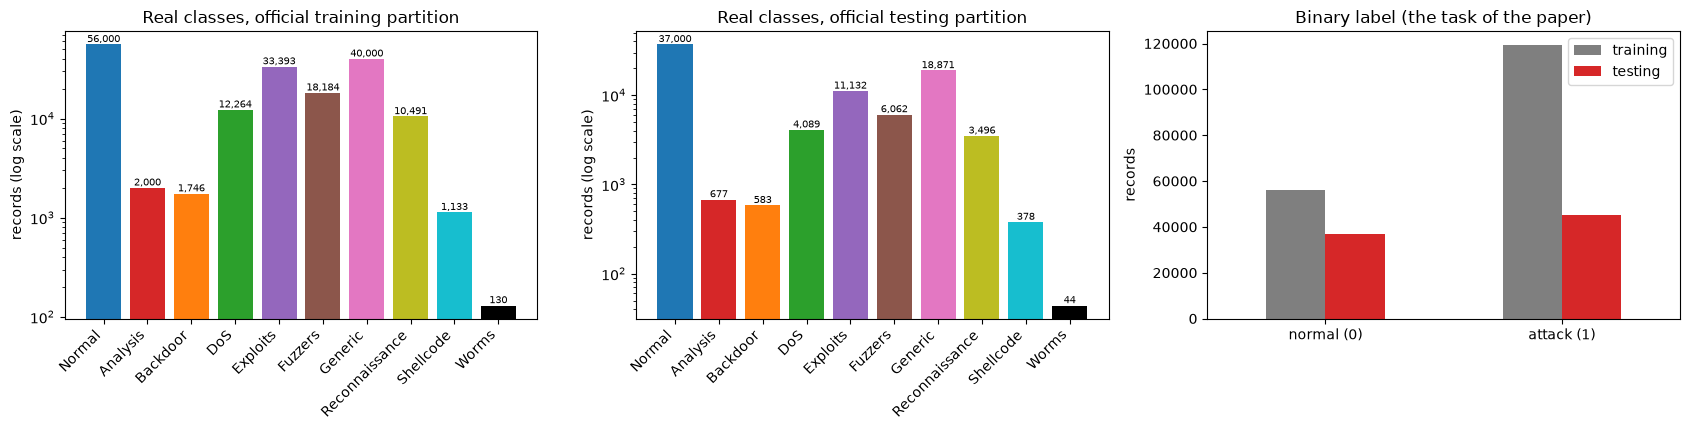

In [6]:
print("Official training partition:", train_part.shape[0], "records;  official testing partition:", test_part.shape[0], "records;",
      len(ALL_FEATURES), "features + attack_cat + label")
print("All feature names:\n ", ", ".join(ALL_FEATURES))
print("\nFeatures used by the paper (Table 2), one per qubit:", FEATURES)
print("\nOriginal label values: label = 0 (normal) / 1 (attack); attack_cat = the nine attack types or Normal")
lab = pd.DataFrame({"training partition": train_part["attack_cat"].value_counts(), "testing partition": test_part["attack_cat"].value_counts()}).reindex(CATS)
lab.loc["total"] = lab.sum()
display(lab)
print("binary label counts  training:", train_part["label"].value_counts().to_dict(), "| testing:", test_part["label"].value_counts().to_dict())

fig, axes = plt.subplots(1, 3, figsize=(17, 4.4))
xs = np.arange(len(CATS)); w = 0.4
for ax, (name, d) in zip(axes[:2], (("training partition", train_part), ("testing partition", test_part))):
    cnt = d["attack_cat"].value_counts().reindex(CATS)
    ax.bar(xs, cnt.values, color=[CAT_COLOR[c] for c in CATS]); ax.set_yscale("log")
    ax.set_xticks(xs); ax.set_xticklabels(CATS, rotation=45, ha="right"); ax.set_ylabel("records (log scale)"); ax.set_title(f"Real classes, official {name}")
    for i, v in enumerate(cnt.values): ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=7)
b = pd.DataFrame({"training": train_part["label"].value_counts().sort_index(), "testing": test_part["label"].value_counts().sort_index()})
b.index = ["normal (0)", "attack (1)"]; b.plot.bar(ax=axes[2], rot=0, color=["tab:gray", "tab:red"]); axes[2].set_title("Binary label (the task of the paper)"); axes[2].set_ylabel("records")
plt.tight_layout(); plt.show()

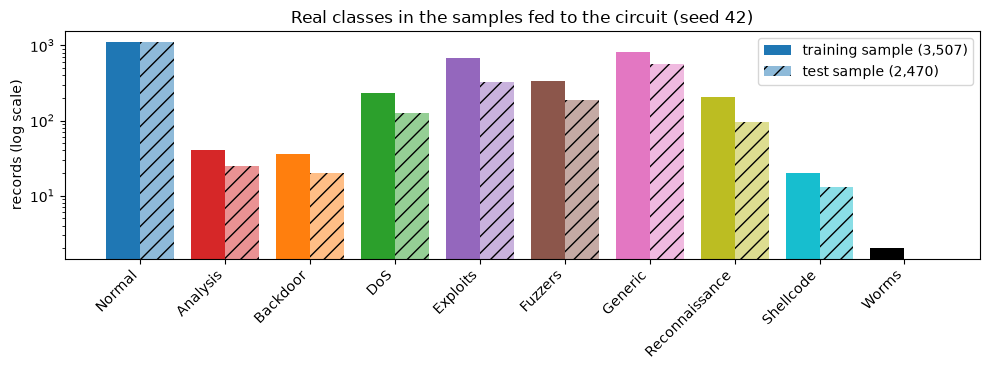

sample shapes: train (3507, 10) | test (2470, 10) | columns: ['sttl', 'ct_dst_src_ltm', 'tcprtt', 'smeansz', 'sbytes', 'ct_dst_sport_ltm', 'dbytes', 'ct_srv_dst', 'ct_srv_src', 'dur']


,sttl,ct_dst_src_ltm,tcprtt,smeansz,sbytes,ct_dst_sport_ltm,dbytes,ct_srv_dst,ct_srv_src,dur,attack_cat
0,0.748,0.000,0.342,0.130,0.325,0.000,0.781,0.000,0.000,0.319,Exploits
1,0.625,0.000,0.001,0.299,0.366,0.000,0.546,0.201,0.000,0.002,Normal
2,0.748,0.117,0.421,0.078,0.275,0.000,0.469,0.000,0.000,0.404,Exploits
3,1.000,0.617,0.000,0.103,0.075,0.772,0.000,0.620,0.617,0.000,Generic
4,1.000,0.317,0.201,0.134,0.219,0.000,0.372,0.318,0.540,0.113,Normal


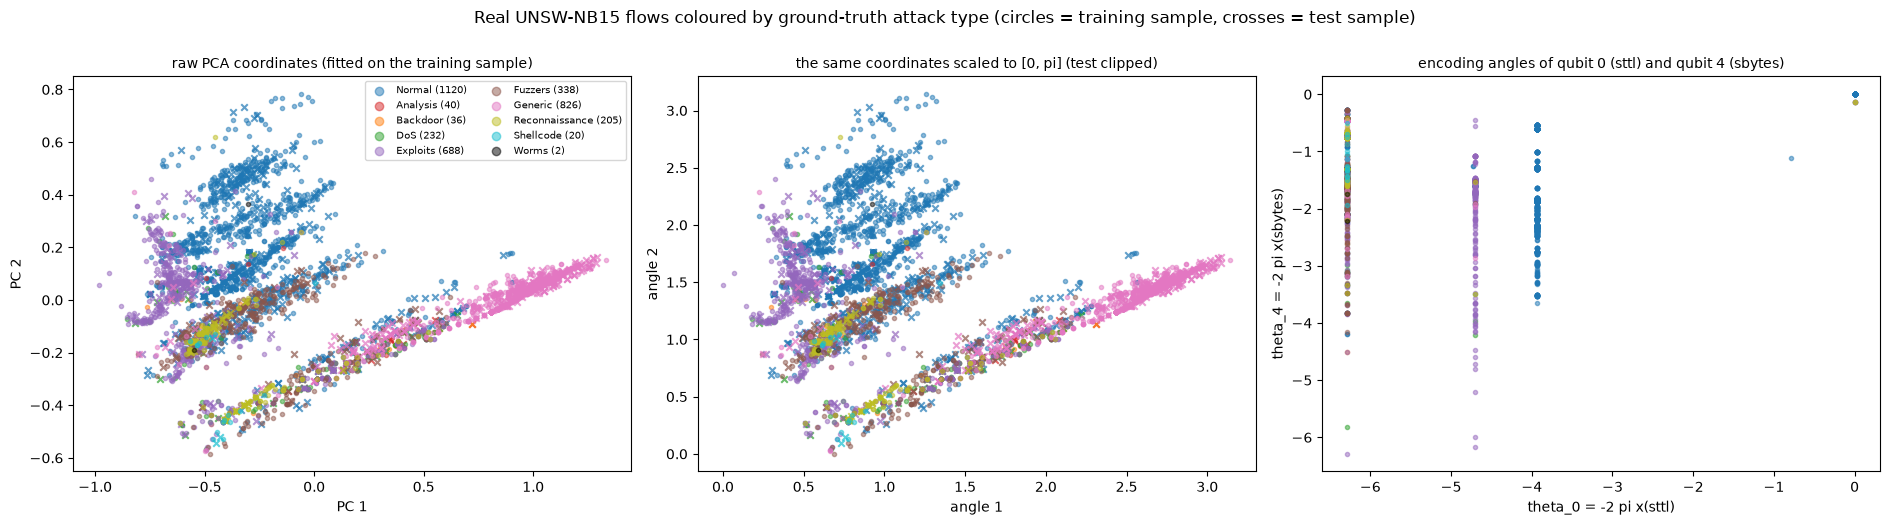

explained variance of the two PCA axes (training sample): [0.649 0.104]


In [7]:
# the samples that the models actually see (seed = SEED), by ground-truth attack type
fig, ax = plt.subplots(figsize=(10, 3.8))
ctr = s0["tr"]["attack_cat"].value_counts().reindex(CATS).fillna(0).astype(int); cte = s0["te"]["attack_cat"].value_counts().reindex(CATS).fillna(0).astype(int)
ax.bar(xs - w / 2, ctr.values, w, label=f"training sample ({len(s0['ytr']):,})", color=[CAT_COLOR[c] for c in CATS])
ax.bar(xs + w / 2, cte.values, w, label=f"test sample ({len(s0['yte']):,})", color=[CAT_COLOR[c] for c in CATS], alpha=0.5, hatch="//")
ax.set_yscale("log"); ax.set_xticks(xs); ax.set_xticklabels(CATS, rotation=45, ha="right"); ax.set_ylabel("records (log scale)"); ax.legend()
ax.set_title("Real classes in the samples fed to the circuit (seed %d)" % SEED)
plt.tight_layout(); plt.show()
print("sample shapes: train", s0["Xtr"].shape, "| test", s0["Xte"].shape, "| columns:", FEATURES)
display(pd.DataFrame(s0["Xtr"][:5], columns=FEATURES).assign(attack_cat=s0["tr"]["attack_cat"][:5].values).round(3))

# 2-D view of the real records: PCA fitted on the TRAINING sample only; then the same coordinates scaled to [0, pi]; then two of the encoding angles
pca = PCA(n_components=2, random_state=SEED).fit(s0["Xtr"])
Ptr, Pte = pca.transform(s0["Xtr"]), pca.transform(s0["Xte"])
sc_pi = MinMaxScaler((0, np.pi)).fit(Ptr)
Atr, Ate = sc_pi.transform(Ptr), np.clip(sc_pi.transform(Pte), 0, np.pi)
ang = -2 * np.pi * s0["Xtr"]                                  # the angles theta_i = -2 pi x_i that the circuit's Ry gates apply
rs = np.random.default_rng(SEED)
itr = rs.choice(len(Ptr), size=min(3000, len(Ptr)), replace=False); ite = rs.choice(len(Pte), size=min(800, len(Pte)), replace=False)
fig, axes = plt.subplots(1, 3, figsize=(19, 5.2))
panels = [(Ptr, Pte, "raw PCA coordinates (fitted on the training sample)", "PC 1", "PC 2"),
          (Atr, Ate, "the same coordinates scaled to [0, pi] (test clipped)", "angle 1", "angle 2"),
          (None, None, "encoding angles of qubit 0 (sttl) and qubit 4 (sbytes)", "theta_0 = -2 pi x(sttl)", "theta_4 = -2 pi x(sbytes)")]
for ax, (A, Bt, title, xl, yl) in zip(axes, panels):
    for c in CATS:
        mtr = (s0["tr"]["attack_cat"].to_numpy()[itr] == c)
        if A is None:
            ax.scatter(ang[itr][mtr, 0], ang[itr][mtr, 4], s=9, alpha=0.5, c=CAT_COLOR[c], label=f"{c} ({int((s0['tr']['attack_cat'] == c).sum())})")
        else:
            ax.scatter(A[itr][mtr, 0], A[itr][mtr, 1], s=9, alpha=0.5, c=CAT_COLOR[c], label=f"{c} ({int((s0['tr']['attack_cat'] == c).sum())})")
            mte = (s0["te"]["attack_cat"].to_numpy()[ite] == c)
            if mte.sum(): ax.scatter(Bt[ite][mte, 0], Bt[ite][mte, 1], s=22, marker="x", c=CAT_COLOR[c], alpha=0.7)
    ax.set_title(title, fontsize=10); ax.set_xlabel(xl); ax.set_ylabel(yl)
axes[0].legend(fontsize=7, markerscale=2, ncol=2)
plt.suptitle("Real UNSW-NB15 flows coloured by ground-truth attack type (circles = training sample, crosses = test sample)", y=1.0)
plt.tight_layout(); plt.show()
print("explained variance of the two PCA axes (training sample):", pca.explained_variance_ratio_.round(3))

## 3. Classical baselines on the same ten features

The paper compares with ANN, LR, KNN, SVM and DT, quoting the settings of its reference [67] (150 hidden neurons; LR with `random_state=10` and 1000 iterations;
k = 9; rbf kernel; tree depth 9). We use those settings on **exactly the same scaled ten-feature inputs** as the quantum model, add a random forest, and also give
DT / RF the full 42-feature table as a reminder of what the ten features cost. Positive class = attack throughout; FAR = (FPR + FNR) / 2 as in Eq. 16.

In [8]:
def metrics_dict(y, pred):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    fpr = fp / max(fp + tn, 1); fnr = fn / max(tp + fn, 1)
    return dict(accuracy=100 * accuracy_score(y, pred), precision=100 * precision_score(y, pred, zero_division=0),
                recall=100 * recall_score(y, pred, zero_division=0), f1=100 * f1_score(y, pred, zero_division=0),
                fpr=100 * fpr, fnr=100 * fnr, far=100 * (fpr + fnr) / 2, tn=int(tn), fp=int(fp), fn=int(fn), tp=int(tp))

def classical_models(seed):
    # hyper-parameters from Section 4.3.2 (quoted from the paper's reference [67]); max_iter of the ANN is a CHOICE
    return {"ANN": MLPClassifier(hidden_layer_sizes=(150,), max_iter=300, random_state=seed),
            "LR": LogisticRegression(random_state=10, max_iter=1000),
            "KNN": KNeighborsClassifier(n_neighbors=9),
            "SVM": SVC(kernel="rbf", random_state=seed),
            "DT": DecisionTreeClassifier(max_depth=9, random_state=seed),
            "RF": RandomForestClassifier(n_estimators=100, random_state=seed, n_jobs=1)}     # the extra baseline required by the factory

def run_classical(split):
    rows = []
    for name, model in classical_models(split["seed"]).items():
        t0 = time.time(); model.fit(split["Xtr"], split["ytr"]); pred = model.predict(split["Xte"]); dt = time.time() - t0
        m = metrics_dict(split["yte"], pred)
        m.update(model=name, inputs="same 10 features", train_acc=100 * float((model.predict(split["Xtr"]) == split["ytr"]).mean()), seconds=dt, seed=split["seed"])
        rows.append(m)
    # extra: tree models on ALL 42 features (numeric as they are, protocol / service / state one-hot), still fitted on the training sample only
    num = [c for c in ALL_FEATURES if c not in CAT_COLS]
    ct = ColumnTransformer([("num", "passthrough", num), ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CAT_COLS)]).fit(split["tr"][ALL_FEATURES])
    Ztr, Zte = ct.transform(split["tr"][ALL_FEATURES]), ct.transform(split["te"][ALL_FEATURES])
    for name, model in {"DT": DecisionTreeClassifier(max_depth=9, random_state=split["seed"]), "RF": RandomForestClassifier(n_estimators=100, random_state=split["seed"], n_jobs=1)}.items():
        t0 = time.time(); model.fit(Ztr, split["ytr"]); pred = model.predict(Zte); dt = time.time() - t0
        m = metrics_dict(split["yte"], pred)
        m.update(model=name, inputs="all 42 features", train_acc=100 * float((model.predict(Ztr) == split["ytr"]).mean()), seconds=dt, seed=split["seed"])
        rows.append(m)
    return rows

CLASSICAL = []
for sd in HEADLINE_SEEDS:
    CLASSICAL += run_classical(get_split(sd))
cl = pd.DataFrame(CLASSICAL)
show = ["train_acc", "accuracy", "precision", "recall", "f1", "fpr", "fnr", "far"]
print(f"Classical models on the test sample, mean over {len(HEADLINE_SEEDS)} seed(s) (positive class = attack):")
display(cl.groupby(["model", "inputs"], sort=False)[show].mean().round(2))
if len(HEADLINE_SEEDS) > 1:
    print("standard deviation over seeds:"); display(cl.groupby(["model", "inputs"], sort=False)[show].std().round(2))

Classical models on the test sample, mean over 2 seed(s) (positive class = attack):


,,train_acc,accuracy,precision,recall,f1,fpr,fnr,far
model,inputs,,,,,,,,
ANN,same 10 features,94.23,81.46,76.83,94.96,84.94,35.09,5.04,20.06
LR,same 10 features,92.00,77.61,73.14,93.79,82.18,42.21,6.21,24.21
KNN,same 10 features,94.67,84.41,79.89,95.81,87.13,29.55,4.19,16.87
SVM,same 10 features,93.57,80.18,73.97,98.75,84.59,42.57,1.25,21.91
DT,same 10 features,96.65,84.72,79.99,96.40,87.42,29.59,3.60,16.60
RF,same 10 features,99.97,86.34,80.87,98.49,88.81,28.56,1.51,15.03
DT,all 42 features,96.99,82.85,77.61,96.80,86.15,34.23,3.20,18.72
RF,all 42 features,100.00,85.36,79.41,99.12,88.18,31.49,0.88,16.18


standard deviation over seeds:


,,train_acc,accuracy,precision,recall,f1,fpr,fnr,far
model,inputs,,,,,,,,
ANN,same 10 features,0.50,0.63,0.51,0.47,0.50,0.83,0.47,0.65
LR,same 10 features,0.75,0.34,0.34,0.05,0.23,0.70,0.05,0.38
KNN,same 10 features,0.52,0.29,0.19,0.31,0.24,0.25,0.31,0.28
SVM,same 10 features,0.38,0.09,0.09,0.00,0.06,0.19,0.00,0.10
DT,same 10 features,0.67,1.40,1.90,0.42,0.96,3.63,0.42,1.61
RF,same 10 features,0.00,0.54,0.63,0.05,0.40,1.15,0.05,0.60
DT,all 42 features,0.30,1.06,1.04,0.36,0.78,1.91,0.36,1.14
RF,all 42 features,0.00,0.31,0.41,0.10,0.21,0.83,0.10,0.36


## Quantum Circuit Architecture

The circuit is built from the paper's description (Sections 3.2 to 3.5, Figs. 3 to 7); wherever the text is silent the choice is listed in the table above.

* **Qubits and encoding.** Ten qubits, one per feature: `H` then `Ry(-2 pi x_i)`.
* **Convolution.** One filter with 6 parameters (`Rz Ry Rz` on each qubit of a pair, then a CNOT from the left to the right qubit), applied to the pairs (0,1), (2,3), (4,5), (6,7), (8,9)
  and then (1,2), (3,4), (5,6), (7,8) with the same parameters (translation invariance).
* **Pooling.** For the pairs (0,1), (2,3), ... a controlled `Rz Ry Rz` on the right qubit, controlled by the left one; the left qubits are dropped, leaving qubits 1, 3, 5, 7, 9 (variant b: 3 parameters;
  variant a adds an `Ry` on the control first: 4 parameters).
* **VQNN.** N layers on the five kept qubits: `Rz Ry Rz` on every qubit (15 parameters per layer), then CNOTs 1 to 3 to 5 to 7 to 9.
* **Read-out.** Probability of `1` on qubit 9 is the attack score; a record is called an attack when it exceeds 0.5.
* **The QCNN of Fig. 13** repeats convolution + pooling four times (10, 5, 3, 2, 1 qubits) and reads the last qubit.

Two independent checks keep the simulation honest. The model that is **trained** is a compact exact state-vector simulator (`Arch`, `p_attack`, below) that exploits the
structure of the circuit and gives exact gradients through `autograd`. Its output is compared, for every architecture and again for the trained weights, with (i) a **PennyLane `default.qubit` QNode** written gate by
gate and (ii) a **Qiskit circuit**; the assertions below fail if they disagree. The drawings are those of the PennyLane QNode, i.e. of the circuit that is executed.

In [9]:
# ---- the simulator that is trained: exact state vector, written with autograd so that gradients are exact ----
# ---- the model family of the paper: [conv + pool] x L_CP, then a VQNN of depth D, readout on the last kept qubit ----
import autograd.numpy as anp
from autograd import value_and_grad


class Arch:
    """Architecture description. cp_layers = number of conv+pool layers, vqnn_depth = layers of the VQNN, pool = 'a' or 'b'."""
    def __init__(self, cp_layers=1, vqnn_depth=4, pool="b", n=N_QUBITS):
        self.cp_layers, self.vqnn_depth, self.pool, self.n = cp_layers, vqnn_depth, pool, n
        self.conv_pairs, self.pool_pairs, self.kept_after = [], [], []
        kept = list(range(n))
        for _ in range(cp_layers):                                  # CHOICE: nearest neighbours in the list of still-active qubits
            even = [(kept[i], kept[i + 1]) for i in range(0, len(kept) - 1, 2)]
            odd = [(kept[i], kept[i + 1]) for i in range(1, len(kept) - 1, 2)]
            pools = [(kept[i], kept[i + 1]) for i in range(0, len(kept) - 1, 2)]      # control = left, target = right (kept)
            new_kept = [kept[i + 1] for i in range(0, len(kept) - 1, 2)] + ([kept[-1]] if len(kept) % 2 else [])
            self.conv_pairs.append(even + odd); self.pool_pairs.append(pools); self.kept_after.append(new_kept)
            kept = new_kept
        self.kept = kept                                            # qubits that enter the VQNN / are read out
        self.n_conv, self.n_pool = 6, (3 if pool == "b" else 4)
        self.n_params = cp_layers * (self.n_conv + self.n_pool) + vqnn_depth * len(kept) * 3
    def split(self, theta):
        """flat parameter vector -> (conv[l] (6,), pool[l] (3 or 4,), vqnn (D, k, 3))"""
        o, conv, pool = 0, [], []
        for _ in range(self.cp_layers):
            conv.append(theta[o:o + self.n_conv]); o += self.n_conv
            pool.append(theta[o:o + self.n_pool]); o += self.n_pool
        vq = anp.reshape(theta[o:], (self.vqnn_depth, len(self.kept), 3)) if self.vqnn_depth else None
        return conv, pool, vq
    def describe(self):
        return f"{self.cp_layers} conv+pool layer(s), pooling ({self.pool}), VQNN depth {self.vqnn_depth}, {self.n_params} parameters, kept qubits {self.kept}"

# ---------- gate matrices (autograd-differentiable, vectorised so that the graph stays small) ----------
def rot(w):
    """R(W) = Rz(w0) first, then Ry(w1), then Rz(w2)  ->  matrix Rz(w2) Ry(w1) Rz(w0) (closed form). w[..., 3] -> [..., 2, 2]."""
    a, b, c = w[..., 0], w[..., 1], w[..., 2]
    cb, sb = anp.cos(b / 2), anp.sin(b / 2)
    m00, m01 = cb * anp.exp(-0.5j * (a + c)), -sb * anp.exp(0.5j * (a - c))
    m10, m11 = sb * anp.exp(0.5j * (c - a)), cb * anp.exp(0.5j * (a + c))
    return anp.stack([anp.stack([m00, m01], axis=-1), anp.stack([m10, m11], axis=-1)], axis=-2)
def ry(t):
    return anp.stack([anp.stack([anp.cos(t / 2) + 0j, -anp.sin(t / 2) + 0j], axis=-1), anp.stack([anp.sin(t / 2) + 0j, anp.cos(t / 2) + 0j], axis=-1)], axis=-2)
def kron2(A, B):
    return anp.reshape(anp.einsum("ij,kl->ikjl", A, B), (A.shape[0] * B.shape[0], A.shape[1] * B.shape[1]))
CNOT4 = np.array([[1, 0, 0, 0], [0, 1, 0, 0], [0, 0, 0, 1], [0, 0, 1, 0]], dtype=complex)
I2 = np.eye(2, dtype=complex)
E0, E1 = np.diag([1.0, 0.0]).astype(complex), np.diag([0.0, 1.0]).astype(complex)
def conv_gate(w):
    """Convolution circuit 10 (our reading): Rz Ry Rz on both qubits (6 parameters), then CNOT(a -> b)."""
    R = rot(anp.reshape(w, (2, 3)))
    return anp.matmul(CNOT4, kron2(R[0], R[1]))
def pool_gate(w, kind):
    """Pooling: Rz Ry Rz on the target controlled by the control qubit (b); (a) additionally starts with Ry(w3) on the control."""
    top = np.kron(E0, I2) + kron2(E1, rot(w[0:3]))
    return top if kind == "b" else anp.matmul(top, kron2(ry(w[3]), I2))
# ---------- state-vector machinery (batch index LAST, so that gates on neighbouring qubits are plain matrix products) ----------
def encode_states(X):
    """H on every qubit, then Ry(-2 pi x_i): product state for each row of X. Shape (2,)*n + (B,); axis q is qubit q.
    The angles are data, not parameters, so this part is plain numpy."""
    th = -2.0 * np.pi * np.asarray(X, float)                                   # (B, n)
    c, s = np.cos(th / 2), np.sin(th / 2)
    v = np.stack([c - s, s + c], axis=1) / np.sqrt(2.0)                        # Ry(th)|+>  -> (B, 2, n)
    S = v[:, :, 0].T                                                           # (2, B)
    for i in range(1, v.shape[2]):
        S = S[..., None, :] * v[:, :, i].T                                     # append qubit i before the batch axis
    return S.astype(complex)

def apply2(S, order, G, a, b):
    """Apply the 4x4 gate G to logical qubits (a, b) (a = control / first). `order` lists which logical qubit sits on each axis;
    the two qubits are moved to the front, so the gate is ONE big matrix product, and the new order is returned (no moving back)."""
    ia, ib = order.index(a), order.index(b)
    axes = [ia, ib] + [i for i in range(len(order)) if i not in (ia, ib)]
    St = S if axes == list(range(len(axes))) else anp.transpose(S, axes + [len(order)])
    sh = St.shape
    return anp.reshape(anp.matmul(G, anp.reshape(St, (4, -1))), sh), [order[i] for i in axes]
def vqnn_unitary(vq, k):
    """Product of the VQNN layers as one 2^k x 2^k unitary: per layer R(W) on every kept qubit, then a CNOT chain 0 -> 1 -> ... -> k-1."""
    dim = 2 ** k
    perm = np.arange(dim)                                                       # CHOICE: CNOT chain on the kept qubits in order
    bits = ((perm[:, None] >> np.arange(k - 1, -1, -1)) & 1)
    for j in range(k - 1):
        bits[:, j + 1] ^= bits[:, j]
    new = (bits * (1 << np.arange(k - 1, -1, -1))).sum(1)
    P = np.zeros((dim, dim), dtype=complex); P[new, perm] = 1.0                  # |x> -> |CNOT chain(x)>
    U = np.eye(dim, dtype=complex)
    R = rot(vq)                                                                  # (D, k, 2, 2)
    letters = "abcdefghijklmnopqrstuvwxyz"
    spec = ",".join(letters[2 * j] + letters[2 * j + 1] for j in range(k)) + "->" + "".join(letters[2 * j] for j in range(k)) + "".join(letters[2 * j + 1] for j in range(k))
    for l in range(vq.shape[0]):
        K = anp.reshape(anp.einsum(spec, *[R[l, j] for j in range(k)]), (dim, dim))   # R_0 (x) R_1 (x) ... (x) R_{k-1}
        U = anp.matmul(P, anp.matmul(K, U))
    return U

def forward_state(theta, S0, arch):
    conv, pool, vq = arch.split(theta); S = S0; order = list(range(arch.n))
    for l in range(arch.cp_layers):
        G = conv_gate(conv[l])
        for (a, b) in arch.conv_pairs[l]: S, order = apply2(S, order, G, a, b)
        P = pool_gate(pool[l], arch.pool)
        for (a, b) in arch.pool_pairs[l]: S, order = apply2(S, order, P, a, b)
    return S, order

def p_attack(theta, S0, arch):
    """P(attack) = probability to read |1> on the last kept qubit (exact, no shots)."""
    S, order = forward_state(theta, S0, arch); n = arch.n; kept = arch.kept; k = len(kept); B = S.shape[-1]
    rest = [q for q in range(n) if q not in kept]
    S = anp.reshape(anp.transpose(S, [order.index(q) for q in rest + kept] + [n]), (2 ** len(rest), 2 ** k, B))
    if arch.vqnn_depth:
        S = anp.matmul(vqnn_unitary(arch.split(theta)[2], k), S)                 # psi' = U psi
    prob = anp.real(S * anp.conj(S))                                             # (rest, kept, B)
    prob = anp.reshape(prob, (2 ** len(rest), 2 ** (k - 1), 2, B))
    return anp.sum(prob[:, :, 1, :], axis=(0, 1))

def mse_loss(theta, S0, y, arch):
    return anp.mean((p_attack(theta, S0, arch) - y) ** 2)
loss_and_grad = value_and_grad(mse_loss)

VQNN-QCNN, pooling (b), N=4: simulator = PennyLane QNode = Qiskit circuit for 8 records (max |difference| 2.6e-15): equivalence verified


QCNN, 4 conv+pool layers (Fig. 13): simulator = PennyLane QNode = Qiskit circuit for 8 records (max |difference| 2.9e-15): equivalence verified


VQNN-QCNN, pooling (a), N=4: simulator = PennyLane QNode = Qiskit circuit for 8 records (max |difference| 2.9e-15): equivalence verified


VQNN-QCNN, pooling (b), N=1: simulator = PennyLane QNode = Qiskit circuit for 8 records (max |difference| 2.3e-15): equivalence verified


VQNN-QCNN, pooling (b), N=6: simulator = PennyLane QNode = Qiskit circuit for 8 records (max |difference| 2.7e-15): equivalence verified


,qubits,circuit_depth,gates,trainable_parameters,two_qubit_gates,kept_qubits
architecture,,,,,,
"VQNN-QCNN, pooling (b), N=4",10,35,174,69,40,"[1, 3, 5, 7, 9]"
"QCNN, 4 conv+pool layers (Fig. 13)",10,42,159,36,43,[9]
"VQNN-QCNN, pooling (a), N=4",10,36,179,70,40,"[1, 3, 5, 7, 9]"
"VQNN-QCNN, pooling (b), N=1",10,20,117,24,28,"[1, 3, 5, 7, 9]"
"VQNN-QCNN, pooling (b), N=6",10,45,212,99,48,"[1, 3, 5, 7, 9]"


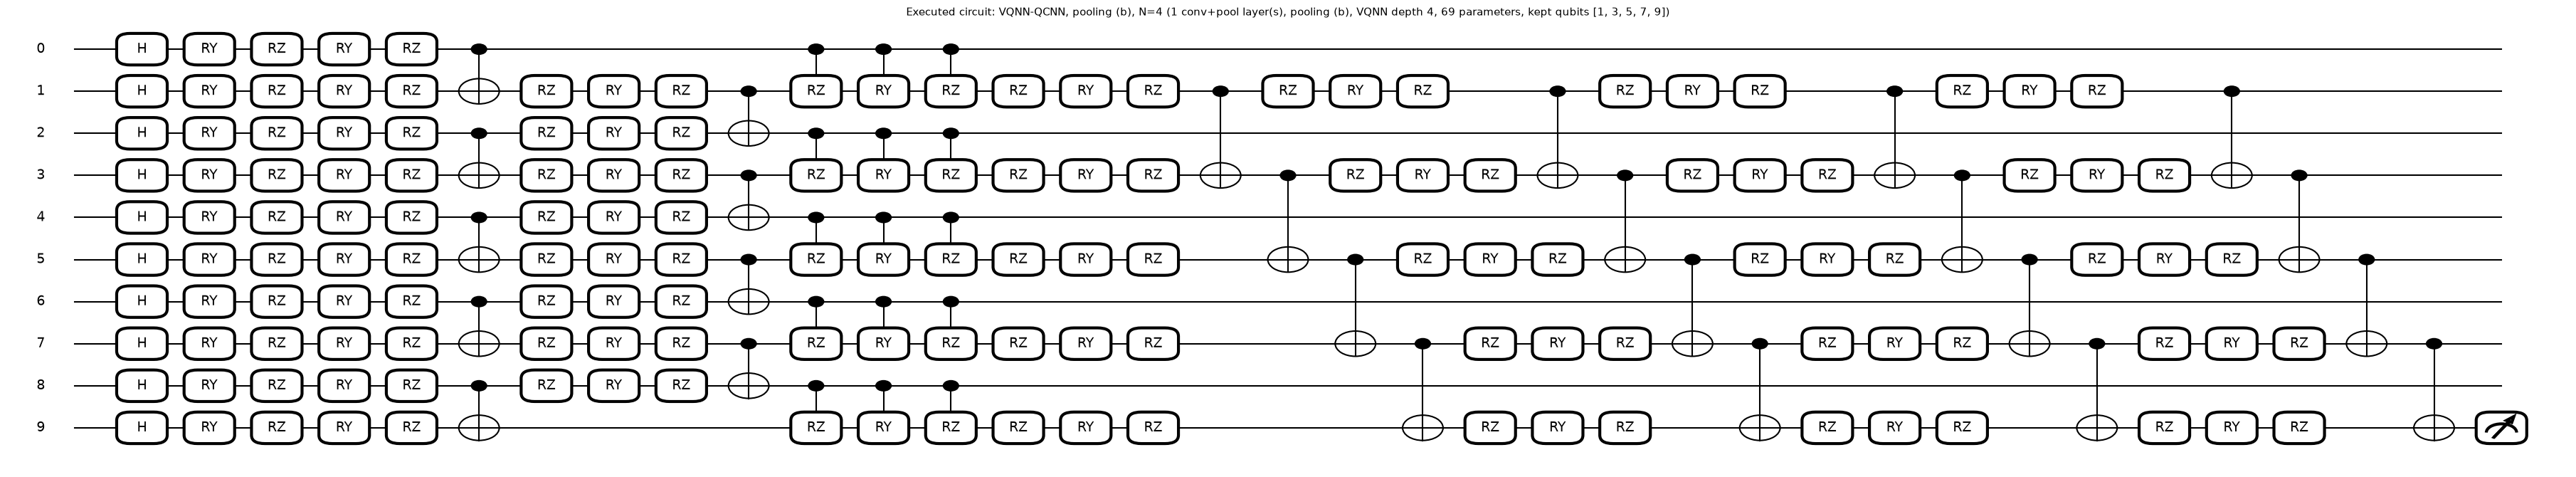

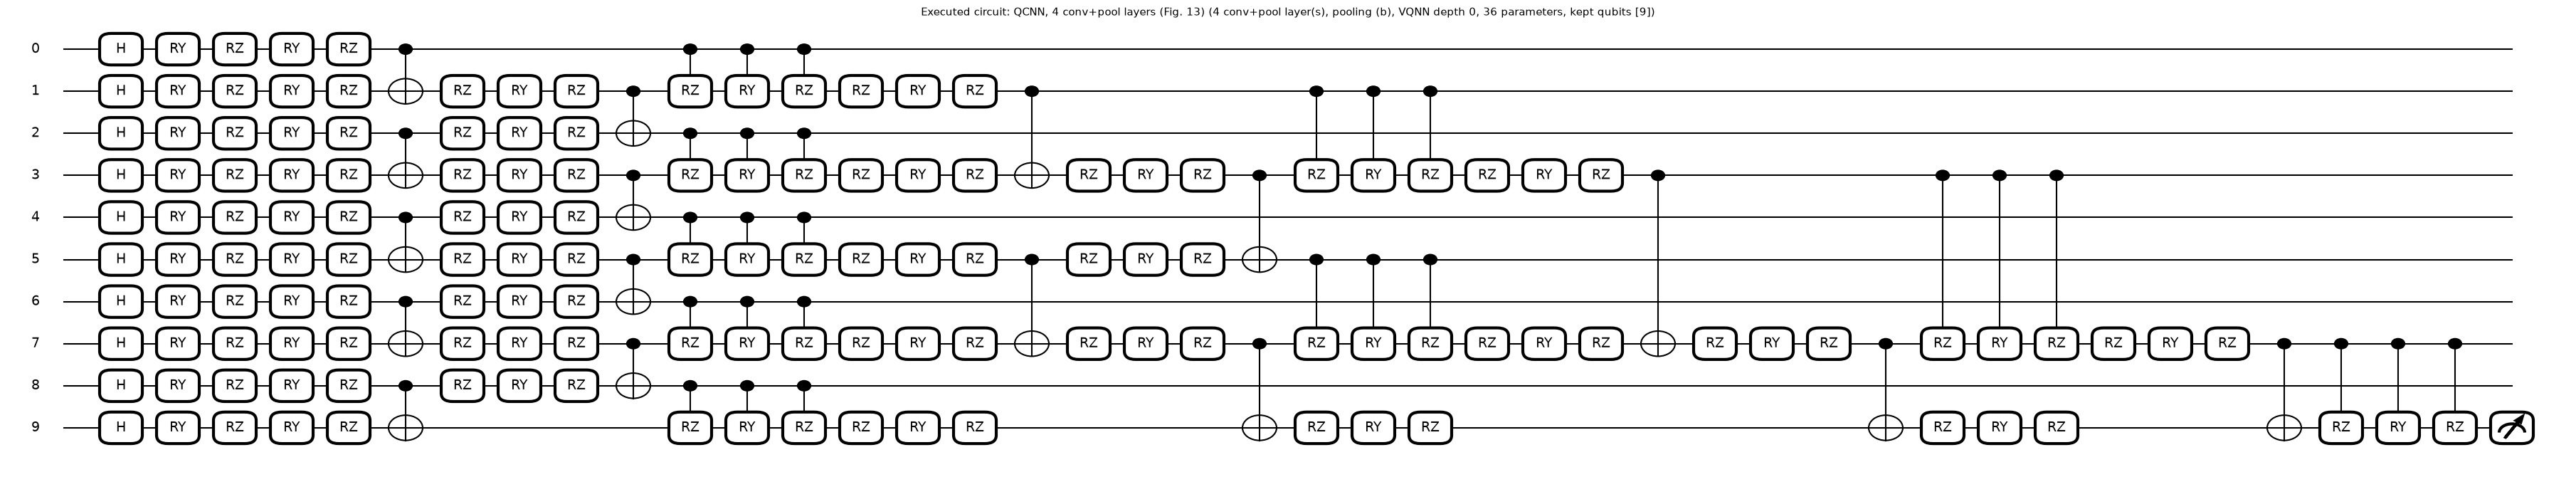

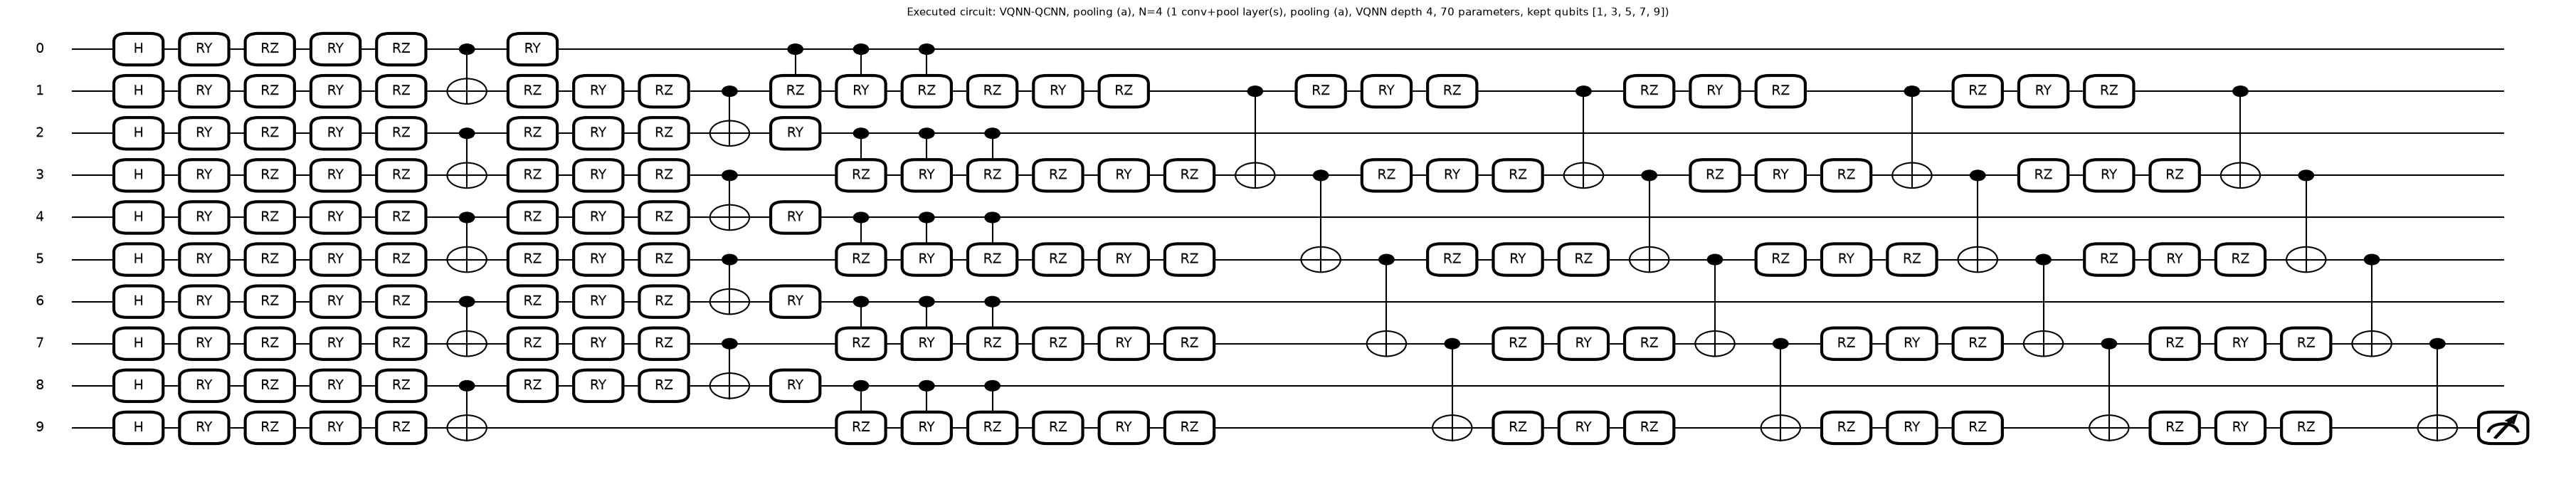

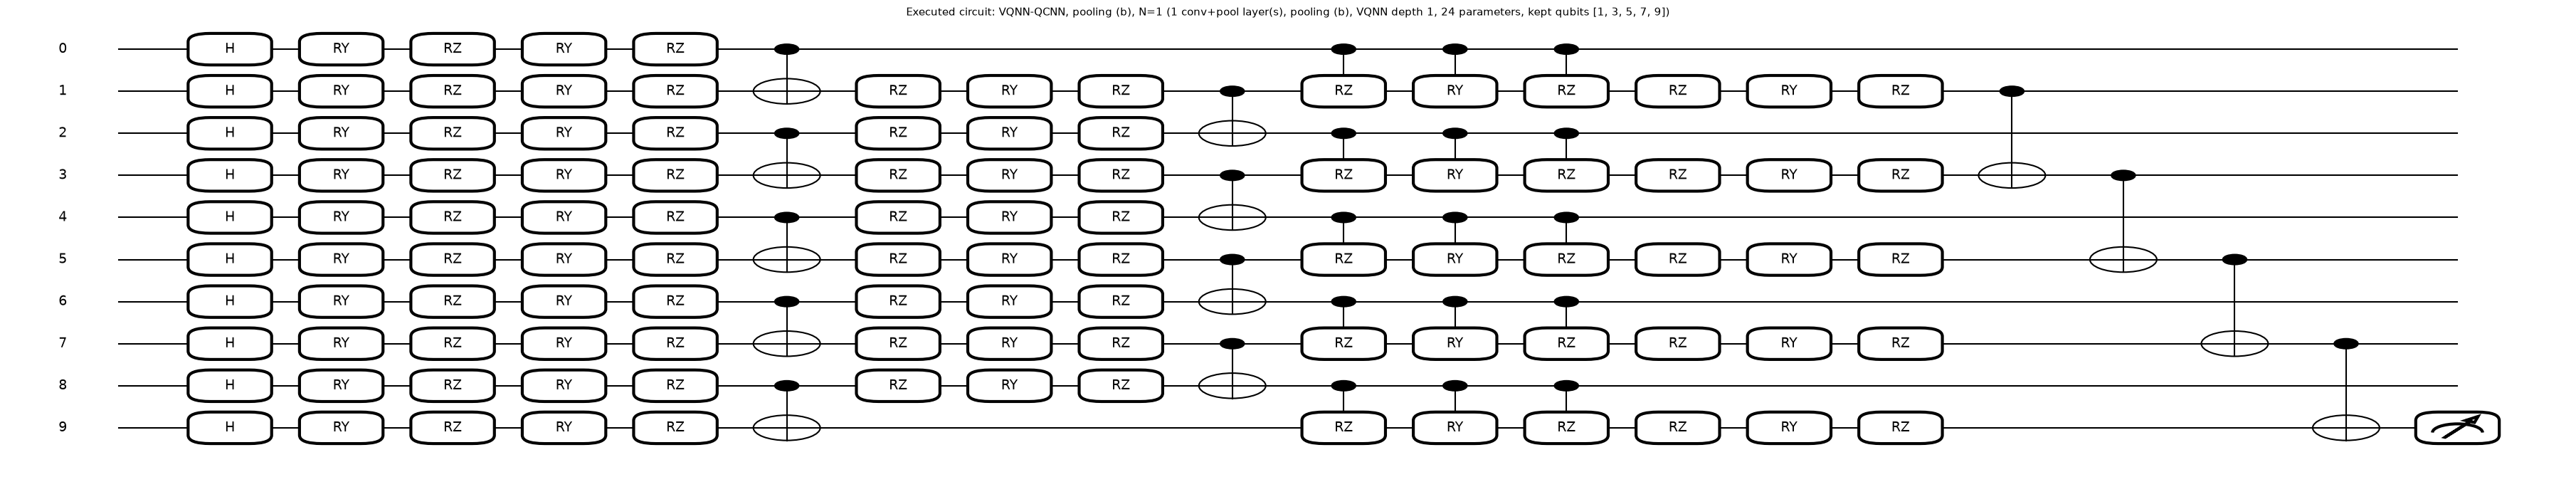

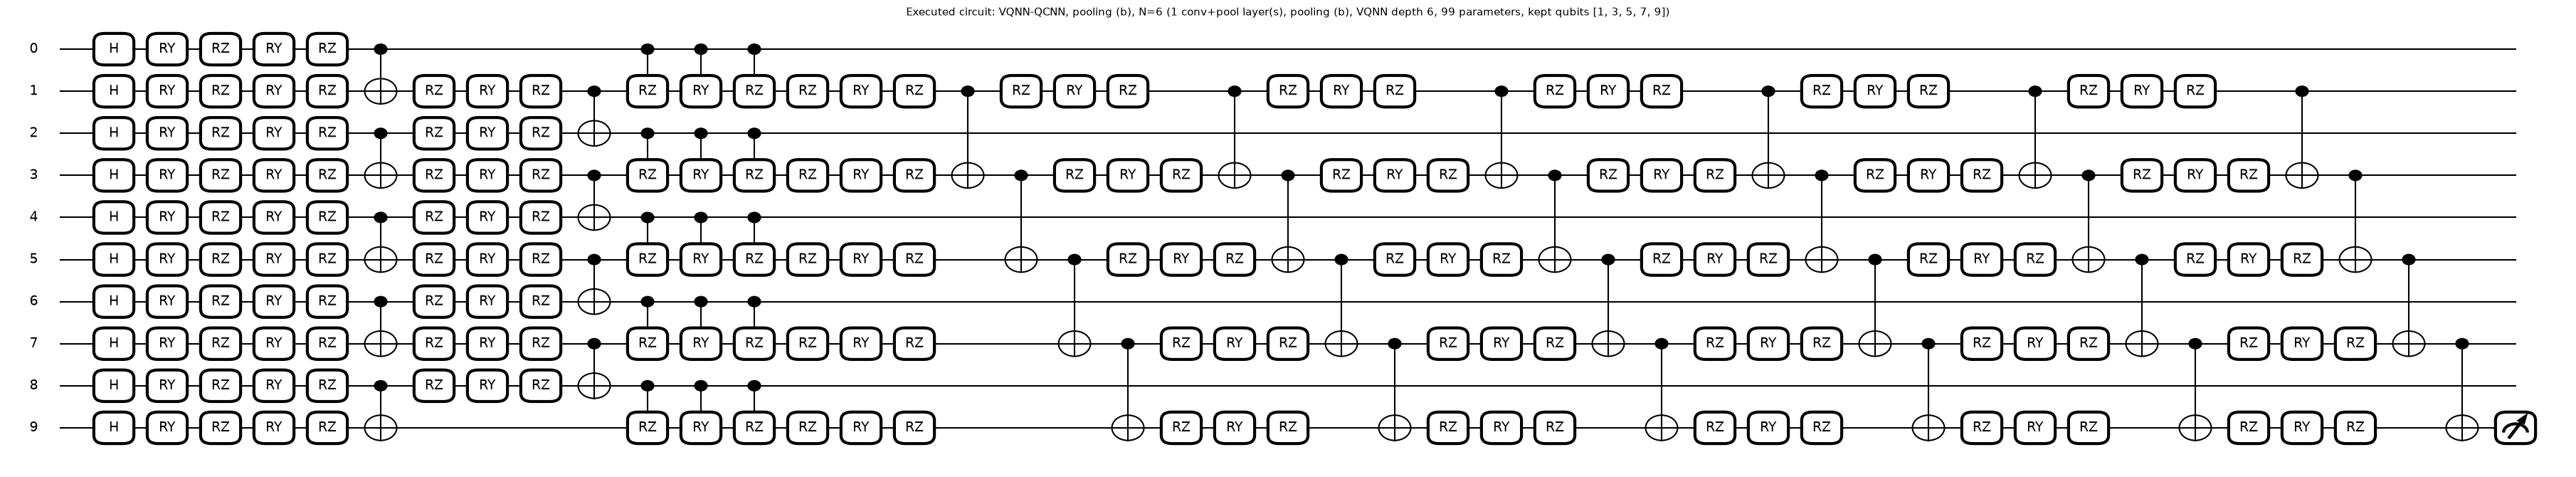

In [10]:
import pennylane as qml
from qiskit import QuantumCircuit, transpile
from qiskit.quantum_info import Statevector

def rot_ops(w, q):                                   # R(W): Rz(w0), then Ry(w1), then Rz(w2) (time order)
    qml.RZ(w[0], wires=q); qml.RY(w[1], wires=q); qml.RZ(w[2], wires=q)

def build_qnode(arch):
    """The same circuit as the simulator above, written gate by gate as a PennyLane QNode (this is what is drawn and what the simulator is checked against)."""
    dev = qml.device("default.qubit", wires=arch.n)
    @qml.qnode(dev)
    def circuit(x, theta):
        conv, pool, vq = arch.split(theta)
        for i in range(arch.n):                                                     # quantum state encoding (Fig. 4): H, then Ry(-2 pi x_i)
            qml.Hadamard(wires=i); qml.RY(-2 * np.pi * x[i], wires=i)
        for l in range(arch.cp_layers):
            for (a, b) in arch.conv_pairs[l]:                                       # convolution filter (shared parameters), then CNOT
                rot_ops(conv[l][0:3], a); rot_ops(conv[l][3:6], b); qml.CNOT(wires=[a, b])
            for (a, b) in arch.pool_pairs[l]:                                       # pooling: control qubit a is dropped, target b is kept
                if arch.pool == "a":
                    qml.RY(pool[l][3], wires=a)
                qml.CRZ(pool[l][0], wires=[a, b]); qml.CRY(pool[l][1], wires=[a, b]); qml.CRZ(pool[l][2], wires=[a, b])
        for l in range(arch.vqnn_depth):                                            # VQNN layers on the kept qubits
            for j, q in enumerate(arch.kept):
                rot_ops(vq[l, j], q)
            for j in range(len(arch.kept) - 1):
                qml.CNOT(wires=[arch.kept[j], arch.kept[j + 1]])
        return qml.probs(wires=arch.kept[-1])                                       # P(0), P(1) on the read-out qubit; P(attack) = P(1)
    return circuit

def qiskit_circuit(x, theta, arch, measure=False):
    conv, pool, vq = arch.split(theta)
    qc = QuantumCircuit(arch.n, 1 if measure else 0)
    def rot_q(w, q):
        qc.rz(float(w[0]), q); qc.ry(float(w[1]), q); qc.rz(float(w[2]), q)
    for i in range(arch.n):
        qc.h(i); qc.ry(float(-2 * np.pi * x[i]), i)
    for l in range(arch.cp_layers):
        for (a, b) in arch.conv_pairs[l]:
            rot_q(conv[l][0:3], a); rot_q(conv[l][3:6], b); qc.cx(a, b)
        for (a, b) in arch.pool_pairs[l]:
            if arch.pool == "a":
                qc.ry(float(pool[l][3]), a)
            qc.crz(float(pool[l][0]), a, b); qc.cry(float(pool[l][1]), a, b); qc.crz(float(pool[l][2]), a, b)
    for l in range(arch.vqnn_depth):
        for j, q in enumerate(arch.kept):
            rot_q(vq[l, j], q)
        for j in range(len(arch.kept) - 1):
            qc.cx(arch.kept[j], arch.kept[j + 1])
    if measure:
        qc.measure(arch.kept[-1], 0)
    return qc

def check_equivalence(arch, theta, X, label=""):
    """P(attack) from (1) the autograd state-vector simulator used for training, (2) the PennyLane QNode, (3) the Qiskit circuit."""
    qn = build_qnode(arch)
    p_sim = p_attack(theta, encode_states(X), arch)
    p_pl = np.array([float(qn(x, theta)[1]) for x in X])
    p_qk = np.array([Statevector(qiskit_circuit(x, theta, arch)).probabilities([arch.kept[-1]])[1] for x in X])
    d1, d2 = np.abs(p_sim - p_pl).max(), np.abs(p_sim - p_qk).max()
    assert d1 < 1e-9 and d2 < 1e-9, f"simulator and circuits differ: {d1:.2e}, {d2:.2e}"
    print(f"{label}: simulator = PennyLane QNode = Qiskit circuit for {len(X)} records (max |difference| {max(d1, d2):.1e}): equivalence verified")

ARCHS = {"VQNN-QCNN, pooling (b), N=4": Arch(1, VQNN_DEPTH, "b"),
         "QCNN, 4 conv+pool layers (Fig. 13)": Arch(4, 0, "b"),
         "VQNN-QCNN, pooling (a), N=4": Arch(1, VQNN_DEPTH, "a")}
for d in sorted(set(SWEEP_DEPTHS) - {VQNN_DEPTH}):
    ARCHS[f"VQNN-QCNN, pooling (b), N={d}"] = Arch(1, d, "b")

x_demo = get_split(SEED)["Xte"][:8]
rows = []; GATES = {}
for name, arch in ARCHS.items():
    th_demo = np.random.default_rng(SEED).uniform(0, 2 * np.pi, arch.n_params)
    check_equivalence(arch, th_demo, x_demo, label=name)                                   # (random weights here; repeated with trained weights later)
    qn = build_qnode(arch)
    res = qml.specs(qn)(x_demo[0], th_demo)["resources"]
    GATES[name] = res.num_gates
    rows.append(dict(architecture=name, qubits=arch.n, circuit_depth=res.depth, gates=res.num_gates, trainable_parameters=arch.n_params,
                     two_qubit_gates=sum(v for k, v in res.gate_types.items() if k in ("CNOT", "CRZ", "CRY")), kept_qubits=str(arch.kept)))
display(pd.DataFrame(rows).set_index("architecture"))

others = [k for k in ARCHS if "pooling (b), N=" in k and "N=4" not in k]
for name in ["VQNN-QCNN, pooling (b), N=4", "QCNN, 4 conv+pool layers (Fig. 13)", "VQNN-QCNN, pooling (a), N=4"] + (others[:1] + others[-1:] if len(others) > 1 else others):   # one drawing per distinct architecture family; the other depths repeat the drawn VQNN block
    arch = ARCHS[name]; qn = build_qnode(arch)
    th_demo = np.random.default_rng(SEED).uniform(0, 2 * np.pi, arch.n_params)
    fig, ax = qml.draw_mpl(qn, decimals=None, style="black_white")(x_demo[0], th_demo)
    fig.set_size_inches(min(36, 0.55 * GATES[name] ** 0.9 + 6), 6.5)
    fig.suptitle(f"Executed circuit: {name} ({arch.describe()})", y=1.0, fontsize=11); plt.show()

## 4. Training the VQNN-QCNN

Adam with learning rate 0.01 on the mean squared error between `P(attack)` and the 0 / 1 label, mini-batches of 32, `EPOCHS` passes over the training sample. Cost and gradients come from the
exact state-vector simulation by back-propagation (the paper's TFQ also differentiates a simulator). The learning curve is drawn after every epoch on (up to) 2000 training records and the whole test sample
(the paper's Fig. 9 shows training and validation loss for N = 4).

Headline model: 1 conv+pool layer(s), pooling (b), VQNN depth 4, 69 parameters, kept qubits [1, 3, 5, 7, 9]


epoch  1 | batch loss 0.2242 | train acc 76.50 % | test acc 63.28 % | test MSE 0.2290 | 48 s


epoch  2 | batch loss 0.1968 | train acc 83.90 % | test acc 63.85 % | test MSE 0.2232 | 85 s


epoch  3 | batch loss 0.1702 | train acc 85.65 % | test acc 69.51 % | test MSE 0.2190 | 125 s


epoch  4 | batch loss 0.1431 | train acc 88.25 % | test acc 74.94 % | test MSE 0.1835 | 164 s



seed 42: test accuracy 74.94 % | precision 69.95 % | recall 95.51 % | F1 80.76 % | FAR 27.38 % | train accuracy 88.39 % | train MSE 0.1360 | test MSE 0.1835 | 180 s


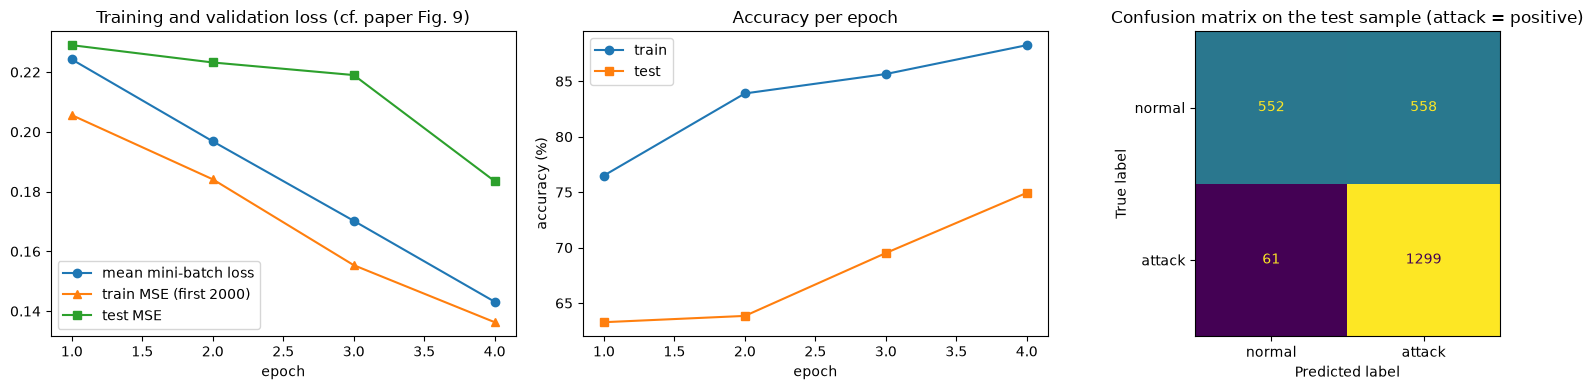

In [11]:
def predict_p(theta, X, arch, chunk=512):
    return np.concatenate([p_attack(theta, encode_states(X[i:i + chunk]), arch) for i in range(0, len(X), chunk)])

RUNS = {}       # (conv+pool layers, VQNN depth, pooling, seed) -> result dict

def train_model(split, arch, seed, epochs=None, verbose=False, track=False):
    key = (arch.cp_layers, arch.vqnn_depth, arch.pool, seed)
    if key in RUNS:
        return RUNS[key]
    epochs = EPOCHS if epochs is None else epochs
    rng_i = np.random.default_rng(seed)
    theta = rng_i.uniform(0, 2 * np.pi, arch.n_params)             # CHOICE: uniform [0, 2 pi) start
    m = np.zeros_like(theta); v = np.zeros_like(theta); step = 0
    b1, b2, eps = 0.9, 0.999, 1e-7                                  # Adam as in TensorFlow (learning rate 0.01 from the paper)
    Xtr, ytr, Xte, yte = split["Xtr"], split["ytr"], split["Xte"], split["yte"]
    n_eval = min(2000, len(ytr)); hist = []; t0 = time.time()
    for ep in range(epochs):
        perm = rng_i.permutation(len(ytr)); batch_loss = []
        for k in range(0, len(perm), BATCH_SIZE):
            idx = perm[k:k + BATCH_SIZE]
            loss, g = loss_and_grad(theta, encode_states(Xtr[idx]), ytr[idx], arch)
            step += 1; m = b1 * m + (1 - b1) * g; v = b2 * v + (1 - b2) * g * g
            theta = theta - LEARNING_RATE * (m / (1 - b1 ** step)) / (np.sqrt(v / (1 - b2 ** step)) + eps)
            batch_loss.append(float(loss))
        if not (track or verbose or ep == epochs - 1):          # evaluate after every epoch only when a learning curve is wanted
            continue
        ptr, pte = predict_p(theta, Xtr[:n_eval], arch), predict_p(theta, Xte, arch)
        hist.append(dict(epoch=ep + 1, batch_loss=float(np.mean(batch_loss)), train_mse=float(np.mean((ptr - ytr[:n_eval]) ** 2)), test_mse=float(np.mean((pte - yte) ** 2)),
                         train_acc=100 * float(np.mean((ptr > 0.5) == ytr[:n_eval])), test_acc=100 * float(np.mean((pte > 0.5) == yte)), seconds=time.time() - t0))
        if verbose:
            h = hist[-1]; print(f"epoch {ep + 1:2d} | batch loss {h['batch_loss']:.4f} | train acc {h['train_acc']:.2f} % | test acc {h['test_acc']:.2f} % | test MSE {h['test_mse']:.4f} | {h['seconds']:.0f} s", flush=True)
    p_tr_full = predict_p(theta, Xtr, arch)                         # final numbers on the complete samples
    pte = predict_p(theta, Xte, arch); pred = (pte > 0.5).astype(int)
    res = metrics_dict(yte, pred)
    res.update(arch=arch.describe(), cp_layers=arch.cp_layers, depth=arch.vqnn_depth, pool=arch.pool, seed=seed, epochs=epochs,
               train_acc=100 * float(np.mean((p_tr_full > 0.5) == ytr)), train_mse=float(np.mean((p_tr_full - ytr) ** 2)), test_mse=float(np.mean((pte - yte) ** 2)),
               seconds=time.time() - t0, theta=theta, history=pd.DataFrame(hist), p_test=pte, pred=pred)
    RUNS[key] = res
    return res

def table_of(runs):
    keep = ["seed", "train_acc", "accuracy", "precision", "recall", "f1", "fpr", "fnr", "far", "train_mse", "test_mse", "seconds"]
    return pd.DataFrame([{k: r[k] for k in keep} for r in runs]).set_index("seed")

ARCH_MAIN = ARCHS["VQNN-QCNN, pooling (b), N=4"]
print("Headline model:", ARCH_MAIN.describe())
first = train_model(get_split(SEED), ARCH_MAIN, SEED, verbose=True, track=True)
print(f"\nseed {SEED}: test accuracy {first['accuracy']:.2f} % | precision {first['precision']:.2f} % | recall {first['recall']:.2f} % | F1 {first['f1']:.2f} % | FAR {first['far']:.2f} % | "
      f"train accuracy {first['train_acc']:.2f} % | train MSE {first['train_mse']:.4f} | test MSE {first['test_mse']:.4f} | {first['seconds']:.0f} s")

fig, axes = plt.subplots(1, 3, figsize=(16, 4)); h = first["history"]
axes[0].plot(h.epoch, h.batch_loss, "o-", label="mean mini-batch loss"); axes[0].plot(h.epoch, h.train_mse, "^-", label="train MSE (first 2000)"); axes[0].plot(h.epoch, h.test_mse, "s-", label="test MSE")
axes[0].set_xlabel("epoch"); axes[0].set_title("Training and validation loss (cf. paper Fig. 9)"); axes[0].legend()
axes[1].plot(h.epoch, h.train_acc, "o-", label="train"); axes[1].plot(h.epoch, h.test_acc, "s-", label="test"); axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy (%)"); axes[1].legend(); axes[1].set_title("Accuracy per epoch")
ConfusionMatrixDisplay(confusion_matrix(get_split(SEED)["yte"], first["pred"], labels=[0, 1]), display_labels=["normal", "attack"]).plot(ax=axes[2], colorbar=False)
axes[2].set_title("Confusion matrix on the test sample (attack = positive)")
plt.tight_layout(); plt.show()

### Headline runs over several seeds

Each seed draws a new random 10 % sample and a new random initialisation; the paper's Appendix B (Tables 10 and 11, circuit 10) averages five random initialisations and its mean accuracy 94.51 % / FAR 6.36 % is exactly the N = 4 row of Table 5.

VQNN-QCNN (N = 4, pooling b): 2 run(s), 131 s for the runs not trained above


,train_acc,accuracy,precision,recall,f1,fpr,fnr,far,train_mse,test_mse,seconds
seed,,,,,,,,,,,
42,88.395,74.939,69.952,95.515,80.758,50.270,4.485,27.378,0.136,0.183,179.654
43,81.437,74.777,73.728,84.191,78.613,36.757,15.809,26.283,0.115,0.147,130.613


,train_acc,accuracy,precision,recall,f1,fpr,fnr,far,train_mse,test_mse,seconds
mean,84.916,74.858,71.840,89.853,79.686,43.514,10.147,26.830,0.126,0.165,155.133
std,4.920,0.115,2.671,8.007,1.517,9.555,8.007,0.774,0.015,0.026,34.677


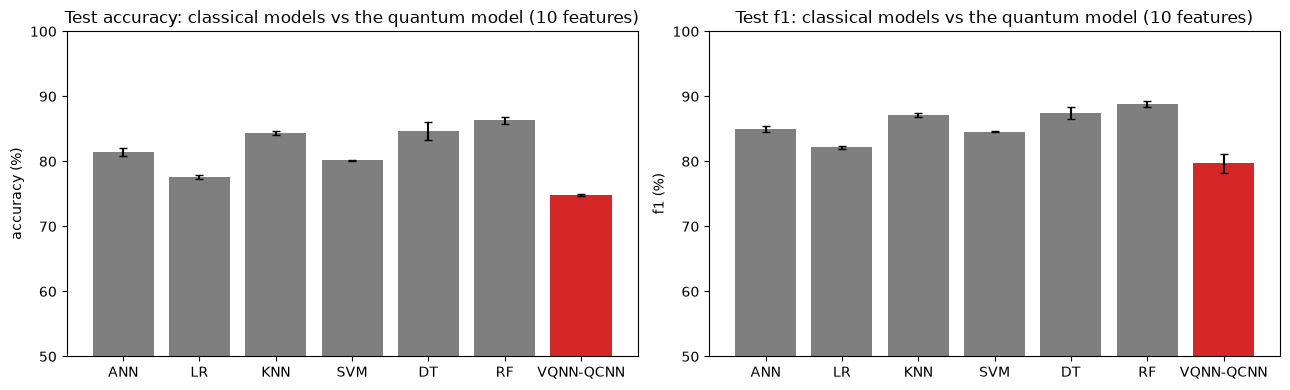

In [12]:
t0 = time.time()
HEAD = [train_model(get_split(sd), ARCH_MAIN, sd) for sd in HEADLINE_SEEDS]
print(f"VQNN-QCNN (N = {VQNN_DEPTH}, pooling b): {len(HEAD)} run(s), {time.time() - t0:.0f} s for the runs not trained above")
th = table_of(HEAD); display(th.round(3))
if len(HEAD) > 1:
    display(th.agg(["mean", "std"]).round(3))

# VQNN-QCNN against the classical models (same samples, same seeds), test F1 and accuracy
order = ["ANN", "LR", "KNN", "SVM", "DT", "RF"]
clm = cl[cl.inputs == "same 10 features"].groupby("model")[["accuracy", "precision", "recall", "f1"]].agg(["mean", "std"])
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for ax, met in zip(axes, ["accuracy", "f1"]):
    means = [clm.loc[n, (met, "mean")] for n in order] + [th[met].mean()]; stds = [np.nan_to_num(clm.loc[n, (met, "std")]) for n in order] + [np.nan_to_num(th[met].std())]
    ax.bar(order + ["VQNN-QCNN"], means, yerr=stds, capsize=3, color=["tab:gray"] * len(order) + ["tab:red"]); ax.set_ylim(50, 100); ax.set_ylabel(met + " (%)")
    ax.set_title(f"Test {met}: classical models vs the quantum model (10 features)")
plt.tight_layout(); plt.show()

## 5. Depth of the VQNN (Table 5, Fig. 8)

The paper trains the VQNN with N = 1 to 6 layers and finds the best test result at N = 4, with N = 5 similar and N = 6 worse. The same sweep is run here (single seed per depth; N = 4 is the headline run).
Wall-clock times are not comparable with the paper's (different simulator and machine).

depth sweep done in 242 s


,accuracy,precision,recall,f1,far,train_mse,test_mse,seconds,parameters
N,,,,,,,,,
1,65.020,66.062,75.000,70.248,36.104,0.196,0.206,115.563,24
4,74.939,69.952,95.515,80.758,27.378,0.136,0.183,179.654,69
6,78.421,75.763,89.412,82.024,22.817,0.107,0.144,126.812,99


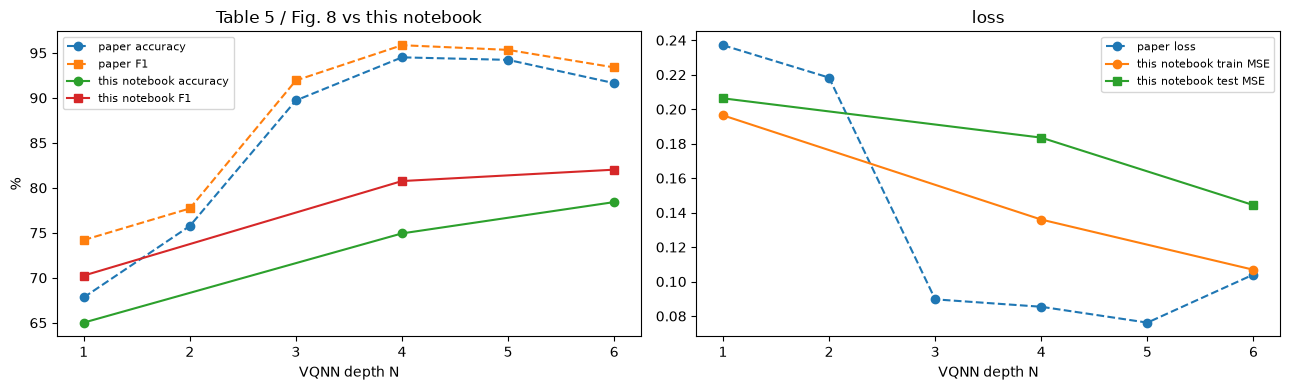

In [13]:
t0 = time.time()
SWEEP = {VQNN_DEPTH: HEAD[:1]}
for d in sorted(set(SWEEP_DEPTHS) - {VQNN_DEPTH}):
    SWEEP[d] = [train_model(get_split(SEED), ARCHS[f"VQNN-QCNN, pooling (b), N={d}"], SEED)]
print(f"depth sweep done in {time.time() - t0:.0f} s")
sw = pd.DataFrame([{**{k: r[k] for k in ["accuracy", "precision", "recall", "f1", "far", "train_mse", "test_mse", "seconds"]}, "N": d} for d, rr in SWEEP.items() for r in rr]).set_index("N").sort_index()
sw["parameters"] = [Arch(1, d, "b").n_params for d in sw.index]
display(sw.round(3))

PAPER_T5 = pd.DataFrame({"N": [1, 2, 3, 4, 5, 6], "time_s": [246, 414, 622, 1132, 1707, 2502], "accuracy": [67.82, 75.76, 89.72, 94.51, 94.23, 91.64],
                         "precision": [75.07, 78.46, 89.00, 96.07, 97.02, 90.32], "recall": [74.21, 65.37, 95.43, 95.83, 93.97, 97.00], "f1": [74.20, 77.71, 91.94, 95.86, 95.34, 93.39],
                         "far": [34.80, 18.69, 12.52, 6.36, 5.65, 10.60], "loss": [0.2371, 0.2183, 0.0897, 0.0854, 0.0762, 0.1041]}).set_index("N")
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(PAPER_T5.index, PAPER_T5.accuracy, "o--", label="paper accuracy"); axes[0].plot(PAPER_T5.index, PAPER_T5.f1, "s--", label="paper F1")
axes[0].plot(sw.index, sw.accuracy, "o-", label="this notebook accuracy"); axes[0].plot(sw.index, sw.f1, "s-", label="this notebook F1")
axes[0].set_xlabel("VQNN depth N"); axes[0].set_ylabel("%"); axes[0].set_title("Table 5 / Fig. 8 vs this notebook"); axes[0].legend(fontsize=8)
axes[1].plot(PAPER_T5.index, PAPER_T5.loss, "o--", label="paper loss"); axes[1].plot(sw.index, sw.train_mse, "o-", label="this notebook train MSE"); axes[1].plot(sw.index, sw.test_mse, "s-", label="this notebook test MSE")
axes[1].set_xlabel("VQNN depth N"); axes[1].set_title("loss"); axes[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

## 6. Pooling variants and the plain QCNN (Table 7, Appendix B)

Two further models are trained on the same samples: the same VQNN-QCNN with pooling circuit (a), and the 4-layer **QCNN of Fig. 13** without VQNN. The paper reports a 4.29 point accuracy advantage of the VQNN-QCNN over the QCNN.

In [14]:
t0 = time.time()
ARCH_Q = ARCHS["QCNN, 4 conv+pool layers (Fig. 13)"]; ARCH_A = ARCHS["VQNN-QCNN, pooling (a), N=4"]
QC = [train_model(get_split(sd), ARCH_Q, sd) for sd in QCNN_SEEDS]
PA = [train_model(get_split(sd), ARCH_A, sd) for sd in POOLA_SEEDS]
print(f"QCNN and pooling-(a) runs: {time.time() - t0:.0f} s")
rows = []
for name, rr in [("VQNN-QCNN, pooling (b)  [headline]", HEAD), ("VQNN-QCNN, pooling (a)", PA), ("QCNN, 4 conv+pool layers (Fig. 13)", QC)]:
    d = table_of(rr).mean()
    rows.append(dict(model=name, runs=len(rr), accuracy=d.accuracy, precision=d.precision, recall=d.recall, f1=d.f1, far=d.far, test_mse=d.test_mse))
cmp7 = pd.DataFrame(rows).set_index("model")
cmp7["parameters"] = [ARCH_MAIN.n_params, ARCH_A.n_params, ARCH_Q.n_params]
display(cmp7.round(2))
print("paper Table 7: VQNN-QCNN accuracy 94.51 % / FAR 6.36 %;  QCNN accuracy 90.22 % / FAR 11.61 %;  improved SVM [68] accuracy 85.99 % / FAR 15.26 % (not re-implemented)")

QCNN and pooling-(a) runs: 283 s


,runs,accuracy,precision,recall,f1,far,test_mse,parameters
model,,,,,,,,
"VQNN-QCNN, pooling (b) [headline]",2,74.86,71.84,89.85,79.69,26.83,0.17,69
"VQNN-QCNN, pooling (a)",1,77.94,75.33,89.12,81.64,23.32,0.16,70
"QCNN, 4 conv+pool layers (Fig. 13)",1,67.25,63.82,93.53,75.87,35.71,0.21,36


paper Table 7: VQNN-QCNN accuracy 94.51 % / FAR 6.36 %;  QCNN accuracy 90.22 % / FAR 11.61 %;  improved SVM [68] accuracy 85.99 % / FAR 15.26 % (not re-implemented)


## 7. The "full-amplitude simulator" test (Section 4.3.3, Figs. 11 and 12)

The paper copies the trained parameters into the circuit of the *Origin Quantum* full-amplitude simulator, measures each of 100 random test records 1000 times and calls the record an attack when
`1` occurs in more than half of the shots; it reports 75 % accuracy for the VQNN-QCNN and 73 % for the QCNN, far below the TFQ result. Origin Quantum is not available here; the same protocol is run on the
Qiskit-Aer state-vector simulator with 1000 shots (an ideal simulator: the only noise is the shot noise of a binomial with 1000 draws, at most 0.016 in probability). That the sampled probabilities match the exact ones is asserted.

100 random test records: 48 attack / 52 normal   (paper: 100 records, 63 attack / 37 normal)


trained VQNN-QCNN: simulator = PennyLane QNode = Qiskit circuit for 8 records (max |difference| 1.7e-15): equivalence verified


trained QCNN: simulator = PennyLane QNode = Qiskit circuit for 8 records (max |difference| 1.9e-15): equivalence verified


shot sampling of 200 circuits x 1000 shots done in 53 s


,accuracy,precision,recall,f1,fpr,fnr,far
VQNN-QCNN (shots),72.0,63.51,97.92,77.05,51.92,2.08,27.00
VQNN-QCNN (exact),72.0,63.51,97.92,77.05,51.92,2.08,27.00
QCNN (shots),55.0,51.76,91.67,66.17,78.85,8.33,43.59
QCNN (exact),55.0,51.72,93.75,66.67,80.77,6.25,43.51


Fig. 11 analogue: one attack record measured 1000 times -> '1' x 808, '0' x 192   (paper: 546 x '1', 454 x '0'; the QCNN gave 528 / 472)


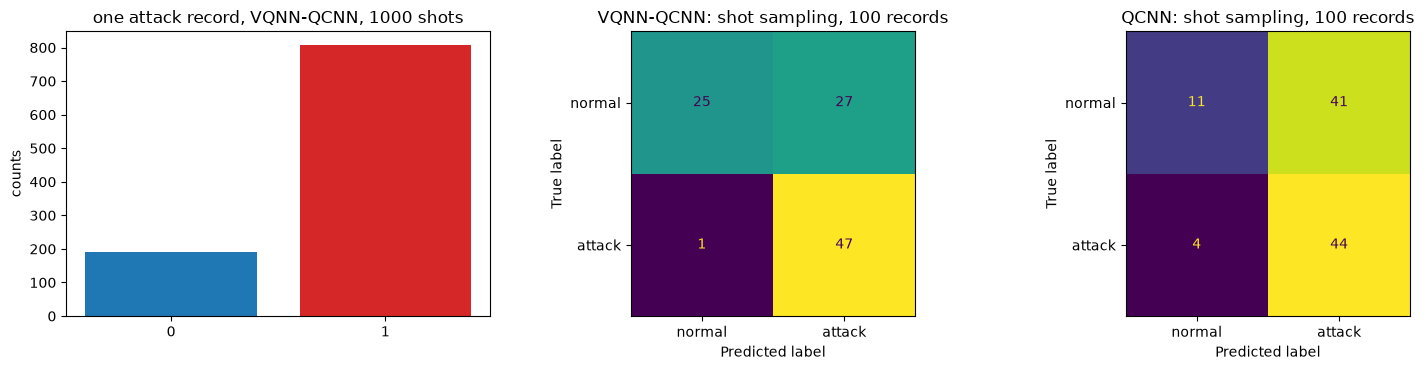

In [15]:
from qiskit_aer import AerSimulator
split_h = get_split(SEED)
run_h = RUNS[(1, VQNN_DEPTH, "b", SEED)]; run_q = RUNS[(4, 0, "b", SEED)] if (4, 0, "b", SEED) in RUNS else QC[0]
rs = np.random.default_rng(SEED)
idx = rs.choice(len(split_h["yte"]), size=min(N_SHOT_RECORDS, len(split_h["yte"])), replace=False)     # CHOICE: random test records in their natural mix
Xs, ys = split_h["Xte"][idx], split_h["yte"][idx]
print(f"{len(idx)} random test records: {int(ys.sum())} attack / {int((1 - ys).sum())} normal   (paper: 100 records, 63 attack / 37 normal)")

# the three implementations must agree for the TRAINED weights as well
check_equivalence(ARCH_MAIN, run_h["theta"], Xs[:8], label="trained VQNN-QCNN")
check_equivalence(ARCH_Q, run_q["theta"], Xs[:8], label="trained QCNN")

simq = AerSimulator(method="statevector", seed_simulator=SEED)     # exact state-vector simulator with shot sampling = an ideal "full-amplitude simulator"
def shots_experiment(arch, theta):
    circs = [qiskit_circuit(x, theta, arch, measure=True) for x in Xs]            # Aer runs these gates natively, no transpilation needed
    res = simq.run(circs, shots=SHOTS, seed_simulator=SEED).result()
    counts = [res.get_counts(j) for j in range(len(circs))]
    return np.array([c.get("1", 0) for c in counts]) / SHOTS, counts

t0 = time.time()
SHOT = {}
for name, arch, run in [("VQNN-QCNN", ARCH_MAIN, run_h), ("QCNN", ARCH_Q, run_q)]:
    p_shot, counts = shots_experiment(arch, run["theta"])
    p_exact = p_attack(run["theta"], encode_states(Xs), arch)
    assert np.abs(p_shot - p_exact).max() < 5 * np.sqrt(0.25 / SHOTS), "shot estimates deviate more than 5 sigma from the exact probabilities"
    pred_shot, pred_exact = (p_shot > 0.5).astype(int), (p_exact > 0.5).astype(int)
    SHOT[name] = dict(shots=metrics_dict(ys, pred_shot), exact=metrics_dict(ys, pred_exact), counts=counts, p_shot=p_shot, p_exact=p_exact)
print(f"shot sampling of {2 * len(idx)} circuits x {SHOTS} shots done in {time.time() - t0:.0f} s")
tab = pd.DataFrame({f"{n} ({k})": {m: SHOT[n][k][m] for m in ["accuracy", "precision", "recall", "f1", "fpr", "fnr", "far"]} for n in SHOT for k in ("shots", "exact")}).T
display(tab.round(2))

j = int(np.flatnonzero(ys == 1)[0]); c = SHOT["VQNN-QCNN"]["counts"][j]
print(f"Fig. 11 analogue: one attack record measured {SHOTS} times -> '1' x {c.get('1', 0)}, '0' x {c.get('0', 0)}   (paper: 546 x '1', 454 x '0'; the QCNN gave 528 / 472)")
fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
axes[0].bar(["0", "1"], [c.get("0", 0), c.get("1", 0)], color=["tab:blue", "tab:red"]); axes[0].set_title("one attack record, VQNN-QCNN, %d shots" % SHOTS); axes[0].set_ylabel("counts")
for ax, n in zip(axes[1:], SHOT):
    ConfusionMatrixDisplay(confusion_matrix(ys, (SHOT[n]["p_shot"] > 0.5).astype(int), labels=[0, 1]), display_labels=["normal", "attack"]).plot(ax=ax, colorbar=False); ax.set_title(f"{n}: shot sampling, {len(idx)} records")
plt.tight_layout(); plt.show()

## 8. Side by side with the paper

Verdict rule: a value is **reproduced** when it is within 2 percentage points (0.02 for the loss values) of the paper's value; otherwise **exceeded** (better than the paper by the stated gap) or **not reached**.
Claims that cannot be tested here are marked **cannot be checked**. The last lines test the paper's own Table 5 for internal consistency.

In [16]:
def verdict(paper, ours, tol=TOL_PTS, lower_is_better=False):
    d = ours - paper
    if abs(d) <= tol: return "reproduced"
    better = (d < 0) if lower_is_better else (d > 0)
    return f"exceeded by {abs(d):.2f}" if better else f"not reached (gap {abs(d):.2f})"

H = table_of(HEAD).mean(); Qm = table_of(QC).mean(); Pm = table_of(PA).mean()
rows = []
def add(claim, paper, ours, lower=False, tol=TOL_PTS, fmt="{:.2f}"):
    rows.append(dict(claim=claim, paper=fmt.format(paper), notebook=fmt.format(ours), verdict=verdict(paper, ours, tol, lower)))
def note(claim, paper, ours, verdict_):
    rows.append(dict(claim=claim, paper=paper, notebook=ours, verdict=verdict_))

# Table 5 / 6, N = 4
add("VQNN-QCNN N=4: test accuracy % (Tables 5, 6, 7)", 94.51, H.accuracy)
add("VQNN-QCNN N=4: precision % (Table 5)", 96.07, H.precision)
add("VQNN-QCNN N=4: recall % (Table 5)", 95.83, H.recall)
add("VQNN-QCNN N=4: F1 % (Table 5)", 95.86, H.f1)
add("VQNN-QCNN N=4: FAR % (Tables 5, 7)", 6.36, H.far, lower=True)
add("VQNN-QCNN N=4: loss (Table 5; compared with our training MSE)", 0.0854, H.train_mse, lower=True, tol=0.02, fmt="{:.4f}")
add("VQNN-QCNN N=4: training accuracy % (Table 6)", 94.41, H.train_acc)
# classical models (Table 6)
PAPER_T6 = {"ANN": (84.39, 78.56, 98.53, 87.42), "LR": (77.64, 73.18, 93.74, 82.20), "KNN": (84.46, 80.31, 95.09, 87.08), "SVM": (60.89, 58.89, 95.88, 72.97), "DT": (90.85, 80.33, 98.38, 88.45)}
clm = cl[cl.inputs == "same 10 features"].groupby("model")[["accuracy", "precision", "recall", "f1"]].mean()
for name, (pa, pp, pr, pf) in PAPER_T6.items():
    add(f"{name}: test accuracy % (Table 6)", pa, clm.loc[name, "accuracy"]); add(f"{name}: F1 % (Table 6)", pf, clm.loc[name, "f1"])
# claims about the ranking
acc_all = {n: clm.loc[n, "accuracy"] for n in PAPER_T6}; acc_all["VQNN-QCNN"] = H.accuracy
best = max(acc_all, key=acc_all.get)
note("VQNN-QCNN has the highest test accuracy of all compared models (Table 6, abstract)", "VQNN-QCNN best", "best: " + best + " (" + ", ".join(f"{k} {v:.1f}" for k, v in acc_all.items()) + f", RF {clm.loc['RF', 'accuracy']:.1f})",
     "reproduced" if best == "VQNN-QCNN" and H.accuracy >= clm.loc["RF", "accuracy"] else "not reached (a classical model on the same 10 features is at least as good)")
# depth trend (Table 5)
if len(sw) > 2:
    best_n = int(sw.accuracy.idxmax())
    note("accuracy improves with depth from N = 1 and is best around N = 4; N = 5, 6 do not help (Table 5, Fig. 8)", "best N=4 (94.51), N=5 94.23, N=6 91.64",
         "accuracy by N: " + ", ".join(f"N={n}: {a:.1f}" for n, a in sw.accuracy.items()) + f"; best N={best_n}",
         ("reproduced" if best_n in (4, 5) and sw.accuracy.iloc[0] < sw.accuracy.max() else "not reached") + ("" if set([1, 2, 3, 4, 5, 6]) <= set(sw.index) else " (partial sweep: only N=" + ",".join(map(str, sw.index)) + ")"))
    add("N = 1 is the weakest depth: accuracy % (Table 5)", 67.82, sw.loc[sw.index.min(), "accuracy"]) if sw.index.min() == 1 else None
# Table 7
add("QCNN (4 conv+pool layers): test accuracy % (Table 7)", 90.22, Qm.accuracy)
add("QCNN: FAR % (Table 7)", 11.61, Qm.far, lower=True)
note("VQNN-QCNN is more accurate than the plain QCNN (+4.29 points, Table 7)", "+4.29", f"{H.accuracy - Qm.accuracy:+.2f}", "reproduced" if H.accuracy - Qm.accuracy > 0 else "not reached (the QCNN is at least as good here)")
note("improved SVM [68]: accuracy 85.99 %, FAR 15.26 % (Table 7)", "85.99 / 15.26", "not re-implemented (reference [68] gives no setup)", "cannot be checked")
# Appendix B (circuit 10 only)
add("Appendix B, circuit 10, pooling (b): mean accuracy % (Table 10)", 94.51, H.accuracy)
add("Appendix B, circuit 10, pooling (a): mean accuracy % (Table 8)", 93.92, Pm.accuracy)
note("Appendix B: circuits 1 to 9 and their ranking (Tables 8 to 11)", "circuit 9 best, circuits 1 and 2 worst", "Fig. 5 is not in the text; only circuit 10 is defined", "cannot be checked")
# full-amplitude simulator (Section 4.3.3)
for name, (pa, pp, pr, pf, pfar) in {"VQNN-QCNN": (75.0, 78.79, 82.54, 80.62, 27.65), "QCNN": (73.0, 77.05, 78.33, 77.68, 28.33)}.items():
    S = SHOT[name]["shots"]
    add(f"{name} on a shot-sampling simulator, 100 records: accuracy % (Section 4.3.3)", pa, S["accuracy"]); add(f"{name} on a shot-sampling simulator: F1 % (Section 4.3.3)", pf, S["f1"])
    add(f"{name} on a shot-sampling simulator: FAR % (Section 4.3.3)", pfar, S["far"], lower=True)
note("a 546 x '1' / 454 x '0' count for one attack record (Fig. 11)", "546 / 454", f"{SHOT['VQNN-QCNN']['counts'][int(np.flatnonzero(ys == 1)[0])].get('1', 0)} / {SHOT['VQNN-QCNN']['counts'][int(np.flatnonzero(ys == 1)[0])].get('0', 0)}", "cannot be checked (different record and trained weights)")
note("training time per pass over the data (Table 5), memory use", "e.g. 1132 s at N=4 (TFQ, Python 3.6, i7-10510U)", f"{H.seconds:.0f} s for {EPOCHS} epochs (own simulator, shared CPU)", "cannot be checked (different framework and machine)")
comparison = pd.DataFrame(rows)
pd.set_option("display.max_colwidth", 100); pd.set_option("display.max_rows", 200)
display(comparison)
print(comparison.verdict.str.extract(r"^(reproduced|exceeded|not reached|cannot be checked)")[0].value_counts().to_dict())

# internal consistency of the paper's own Table 5 row for N = 4
n_att, n_nor = 4534, 3699
tp = 0.9583 * n_att; pp_ = tp / 0.9607; fp = pp_ - tp; tn = n_nor - fp
print(f"\nConsistency check of the paper's N=4 row (test set of {n_att} attack and {n_nor} normal records): recall 95.83 % and precision 96.07 % imply TP = {tp:.0f}, FP = {fp:.0f}, TN = {tn:.0f}, "
      f"hence accuracy = {(tp + tn) / (n_att + n_nor) * 100:.2f} % (reported 94.51 %), FPR = {fp / n_nor * 100:.2f} %, FNR = {(n_att - tp) / n_att * 100:.2f} %, FAR = {(fp / n_nor + (n_att - tp) / n_att) * 50:.2f} % (reported 6.36 %).")
print(f"total notebook run time: {(time.time() - T_NOTEBOOK_START) / 60:.1f} min (FAST_MODE = {FAST_MODE})")

,claim,paper,notebook,verdict
0,"VQNN-QCNN N=4: test accuracy % (Tables 5, 6, 7)",94.51,74.86,not reached (gap 19.65)
1,VQNN-QCNN N=4: precision % (Table 5),96.07,71.84,not reached (gap 24.23)
2,VQNN-QCNN N=4: recall % (Table 5),95.83,89.85,not reached (gap 5.98)
3,VQNN-QCNN N=4: F1 % (Table 5),95.86,79.69,not reached (gap 16.17)
4,"VQNN-QCNN N=4: FAR % (Tables 5, 7)",6.36,26.83,not reached (gap 20.47)
5,VQNN-QCNN N=4: loss (Table 5; compared with our training MSE),0.0854,0.1255,not reached (gap 0.04)
6,VQNN-QCNN N=4: training accuracy % (Table 6),94.41,84.92,not reached (gap 9.49)
7,ANN: test accuracy % (Table 6),84.39,81.46,not reached (gap 2.93)
8,ANN: F1 % (Table 6),87.42,84.94,not reached (gap 2.48)
9,LR: test accuracy % (Table 6),77.64,77.61,reproduced


{'not reached': 22, 'reproduced': 7, 'cannot be checked': 4, 'exceeded': 2}

Consistency check of the paper's N=4 row (test set of 4534 attack and 3699 normal records): recall 95.83 % and precision 96.07 % imply TP = 4345, FP = 178, TN = 3521, hence accuracy = 95.54 % (reported 94.51 %), FPR = 4.81 %, FNR = 4.17 %, FAR = 4.49 % (reported 6.36 %).
total notebook run time: 17.8 min (FAST_MODE = True)


## 9. Reading the paper critically

The measured values are in the tables above (committed run: `FAST_MODE = True`, a 2 % training sample of 3,507 records, 4 epochs, 2 seeds; **not** the paper's budget, so the quantum numbers are those of an under-trained model: the training accuracy was still rising, 88 % after the last epoch). The points below are about *why* the numbers differ and what the paper leaves open.

1. **The architecture is reproducible, the headline number is not (here).** The circuit follows the paper's description and trains (training MSE falls from 0.22 to 0.14 for seed 42), but after 4 epochs on 3.5 k records it reaches 74.9 % test accuracy / F1 79.7 % / FAR 26.8 % against 94.51 % / 95.86 % / 6.36 % in the paper. A paper-scale run (17.5 k records, 20 epochs) costs roughly 75 minutes of a shared CPU per model with this simulator and was **not** run, so whether more training closes the gap is open. What can be said is that none of the ten-feature classical models on the same inputs gets above 86.3 % (random forest) and the decision tree on all 42 features reaches 82.9 %: the paper's 94.51 % would be 8 points above every classical result we obtained on this partition.
2. **The classical baselines are consistent with the paper except SVM and DT.** LR (77.6 % vs 77.64 %) and KNN (84.4 % vs 84.46 %) match to the second decimal; ANN is 3 points lower than the paper; the paper's SVM (60.89 %) is far weaker than a default rbf SVM on scaled features (80.2 %), which suggests the paper's SVM was fed unscaled data; the paper's DT row (90.85 % accuracy with 80.33 % precision and 98.38 % recall) cannot be one confusion matrix of the test set either.
3. **Table 5 is internally inconsistent.** The last cell shows that recall 95.83 % and precision 96.07 % on a test set of 4,534 attack and 3,699 normal records imply accuracy 95.5 %, FPR 4.8 %, FNR 4.2 % and FAR 4.5 %, not 94.51 % and 0.0636. The "Loss" column is not defined (this notebook uses the MSE of the attack probability).
4. **The test sample is not the training distribution.** The official partitions differ: normal traffic is 31.9 % of the training partition but 44.9 % of the testing partition (37,000 / 82,332), and the attack mix changes as well (Exploits 19.0 % against 13.5 %, Fuzzers 10.4 % against 7.4 %). Training accuracy (85 to 88 %) therefore sits well above test accuracy (75 %) for the quantum model, and the classical models show the same gap (about 95 % against 80 to 86 %); the scatter plot above shows heavily overlapping classes in the first two principal components.
5. **The Origin Quantum test shows nothing about quantum noise.** An exact simulator with 1000 shots reproduces the exact probabilities to within shot noise (asserted above), so the paper's drop from 94.51 % to 75 % cannot come from the simulator; it points to a transfer problem (the trained angles were copied by hand between two frameworks, with possibly different gate conventions) or to a particular unlucky set of 100 records. Here the sampled predictions equal the exact ones (72 % on our 100 random records, 48 attack / 52 normal; the paper's records were 63 attack / 37 normal).
6. **Depth study and Appendix B.** The paper's Table 10 average over five initialisations (94.51 % for circuit 10) is identical to the single N = 4 row of Table 5, so Table 5 appears to be a mean, not a single run. In our short runs accuracy rises monotonically with depth (N = 1: 65.0 %, N = 4: 74.9 %, N = 6: 78.4 %), the paper's drop at N = 6 cannot be tested with this budget. Circuits 1 to 9 of Fig. 5 are not in the extracted text, so the choice of circuit 10 cannot be checked.
7. **Resource claims.** The motivation (qubit encoding is shallow and NISQ-friendly) is fair, but 10 qubits are trivially simulated classically (0.6 ms per record forward here), so the paper shows no quantum advantage, and it compares a tuned quantum model with classical models that were not tuned on this data.

## 10. Exercises

1. **Read-out qubit.** Change the read-out from the last kept qubit to the first one, or to the parity of all five. Which choice trains fastest, and why does the paper never say?
2. **Normalisation.** Set `LOG_FEATURES = False` and rerun. Which of the ten features collapses onto almost one angle, and what happens to the accuracy of the quantum model and of the random forest?
3. **Encoding.** The encoding applies `Ry(-2 pi x)` after a Hadamard. Replace it by a plain `Ry(pi x)` on `|0>`. How do the five-qubit reduced states of normal and attack flows change?
4. **Shared filters.** Give every convolution pair its own six parameters instead of sharing them. How many parameters does the circuit have now, and does the depth study of Table 5 change?
5. **Metric mismatch.** Recompute accuracy, FPR, FNR and FAR from the paper's precision and recall for N = 4 (the last cell does this) and find which of the reported numbers cannot belong to the same confusion matrix.